# Westline Carriers – TPMS Analysis
**Notebook 01: Load and clean**
Ritika Raj Parekh · Humaniti AI challenge · Data: TyreSense exports 1 Jun – 15 Jul 2026, 6 trucks

## Section 1 – Connect Google Drive and check files
Mount Drive, point to the Westline_Working folder, and confirm all 19 pack files are present.

In [31]:
# Cell 1 — Connect Google Drive and check the files are visible
from google.colab import drive
drive.mount('/content/drive')

import os
DATA = '/content/drive/MyDrive/Westline_Working/'

files = sorted(os.listdir(DATA))
for f in files:
    size_mb = os.path.getsize(DATA + f) / 1e6
    print(f"{size_mb:7.2f} MB   {f}")
print(f"\nTotal files: {len(files)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  19.19 MB   TyreSense_export_KA22AD7730_2026-06.csv
   9.62 MB   TyreSense_export_KA22AD7730_2026-07.csv
  19.67 MB   TyreSense_export_KA22AG3391_2026-06.csv
   9.80 MB   TyreSense_export_KA22AG3391_2026-07.csv
  15.66 MB   TyreSense_export_KA25AB4471_2026-06.csv
   7.55 MB   TyreSense_export_KA25AB4471_2026-07.csv
  19.69 MB   TyreSense_export_KA25AC1182_2026-06.csv
  10.25 MB   TyreSense_export_KA25AC1182_2026-07.csv
  16.33 MB   TyreSense_export_KA25AE2016_2026-06.csv
   7.99 MB   TyreSense_export_KA25AE2016_2026-07.csv
  14.57 MB   TyreSense_export_KA48AF9054_2026-06.csv
   7.89 MB   TyreSense_export_KA48AF9054_2026-07.csv
   0.01 MB   Westline - Client Brief.docx
   0.01 MB   Westline - Data Dictionary.docx
   0.01 MB   Westline - Fleet Manager Transcript.docx
   0.01 MB   Westline - Task Sheet.docx
   0.01 MB   Westline - Tyre Inflation Spec Sheet.docx

## Section 2 – Load all TyreSense exports and first health check
Combine the 12 CSVs into one table and run five checks:
1. Axles 6 and 7 are empty
2. Vehicle column matches the file name
3. Per-file summary: rows, date range, record interval, gaps, duplicates, missing GPS
4. Overlap between June and July files
5. How often the receiver sends a record

Feeds Assessment Notes: F1, F2, F5, F6, F7

In [ ]:
# Cell 2 — Load all 12 TyreSense files and run a first health check
import pandas as pd, glob, os
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)

SLOTS = ['1LO','1RO','2LO','2RO','3LO','3RO','4LI','4LO','4RI','4RO','5LI','5LO','5RI','5RO']

frames = []
for path in sorted(glob.glob(DATA + 'TyreSense_export_*.csv')):
    d = pd.read_csv(path)
    d['source_file'] = os.path.basename(path)
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
raw['Time'] = pd.to_datetime(raw['Time'])
raw['GPS Time'] = pd.to_datetime(raw['GPS Time'])
# Take the truck ID from the FILE NAME, so we can compare it with the 'Vehicle' column inside the file
raw['truck'] = raw['source_file'].str.extract(r'export_(\w+?)_2026')[0]
print('Total rows:', len(raw), '| columns:', raw.shape[1])

# Check 1: axles 6 and 7 should be completely empty
extra = [c for c in raw.columns if c[:1] in '67']
print('Non-empty values in axle 6/7 columns:', int(raw[extra].notna().sum().sum()))

# Check 2: does the Vehicle column inside each file match the file name?
print('\nVehicle values found per file:')
print(raw.groupby('source_file')['Vehicle'].unique().to_string())

# Check 3: per-file summary
rows = []
for f, g in raw.groupby('source_file'):
    g = g.sort_values('Time')
    gap = g['Time'].diff().dt.total_seconds()
    rows.append({
        'file': f.replace('TyreSense_export_', '').replace('.csv', ''),
        'rows': len(g),
        'first': g['Time'].min(), 'last': g['Time'].max(),
        'median_gap_s': gap.median(),
        'gaps_over_1h': int((gap > 3600).sum()),
        'dup_rows_in_file': int(g.drop(columns='source_file').duplicated().sum()),
        'no_gps_%': round(g['Latitude'].isna().mean() * 100, 1),
    })
print('\n', pd.DataFrame(rows).to_string(index=False))

# Check 4: do the June and July files overlap, and are the overlapping rows identical?
data_cols = [c for c in raw.columns if c not in ('source_file', 'Vehicle')]
print('\nJune/July overlap per truck:')
for t, g in raw.groupby('truck'):
    jun = g[g.source_file.str.contains('2026-06')]
    jul = g[g.source_file.str.contains('2026-07')]
    overlap = jun[jun.Time >= jul.Time.min()]
    identical = g.duplicated(subset=data_cols, keep='first').sum()
    print(f"  {t}: overlap {jul.Time.min()} to {jun.Time.max()}  "
          f"rows in overlap={len(overlap)}  identical duplicate rows={identical}")

# Check 5: how often does the receiver send a record?
gaps = raw.sort_values(['truck', 'Time']).groupby('truck')['Time'].diff().dt.total_seconds()
print('\nMost common gaps between records (seconds, rounded to 10):')
print(gaps.round(-1).value_counts().head(6).to_string())

Total rows: 559179 | columns: 74
Non-empty values in axle 6/7 columns: 0

Vehicle values found per file:
source_file
TyreSense_export_KA22AD7730_2026-06.csv    [KA22AD7730]
TyreSense_export_KA22AD7730_2026-07.csv    [KA22AD7730]
TyreSense_export_KA22AG3391_2026-06.csv    [KA22AG3391]
TyreSense_export_KA22AG3391_2026-07.csv    [KA22AG3391]
TyreSense_export_KA25AB4471_2026-06.csv    [KA25AB4471]
TyreSense_export_KA25AB4471_2026-07.csv     [KA25B4471]
TyreSense_export_KA25AC1182_2026-06.csv    [KA25AC1182]
TyreSense_export_KA25AC1182_2026-07.csv    [KA25AC1182]
TyreSense_export_KA25AE2016_2026-06.csv    [KA25AE2016]
TyreSense_export_KA25AE2016_2026-07.csv    [KA25AE2016]
TyreSense_export_KA48AF9054_2026-06.csv    [KA48AF9054]
TyreSense_export_KA48AF9054_2026-07.csv    [KA48AF9054]

               file  rows               first                last  median_gap_s  gaps_over_1h  dup_rows_in_file  no_gps_%
KA22AD7730_2026-06 67964 2026-06-01 00:00:00 2026-07-01 05:58:30          18.0          

## Section 3 – Remove duplicates, reshape to tyre level, sanity checks
1. Drop the 2,869 June/July duplicate rows (F1)
2. Reshape to one row per truck × time × tyre position, with axle and spec pressure
3. How often each sensor misses a record
4. Physically impossible values (pressure, temperature, battery)
5. Range of pressure and temperature by axle
6. Longest silence per tyre
7. Any tyre that ever read below 70 PSI
8. Save clean tables to Drive (clean_wide.parquet, clean_tyre.parquet)

Feeds Assessment Notes: data-quality checks; H3 (Karwar 5RI)

In [3]:
# Section 3 — Remove duplicates, reshape to one row per tyre reading, sanity checks
import numpy as np

# 3a. Drop the June/July overlap duplicates (F1)
data_cols = [c for c in raw.columns if c not in ('source_file', 'Vehicle')]
df = (raw.drop_duplicates(subset=data_cols, keep='first')
         .drop(columns=extra + ['Vehicle'])          # drop axle 6/7 columns and the unreliable Vehicle field (F2)
         .sort_values(['truck', 'Time'])
         .reset_index(drop=True))
print(f'Rows before: {len(raw):,}  after removing duplicates: {len(df):,}  removed: {len(raw)-len(df):,}')

# 3b. Reshape: one row per truck, time and tyre position
parts = []
for s in SLOTS:
    p = df[['truck', 'Time', 'GPS Time', 'Latitude', 'Longitude', f'{s} PSI', f'{s} TEMP', f'{s} BATT']].copy()
    p.columns = ['truck', 'Time', 'GPS_Time', 'Lat', 'Lon', 'PSI', 'TEMP', 'BATT']
    p['pos'] = s
    parts.append(p)
tyre = pd.concat(parts, ignore_index=True)
tyre['axle'] = tyre['pos'].str[0].astype(int)
tyre['spec'] = tyre['axle'].map({1: 115, 2: 105, 3: 105, 4: 100, 5: 100})
print(f'Tyre-level rows: {len(tyre):,} (= {len(df):,} records x 14 positions)')

# 3c. How often is each sensor missing from a record?
miss = tyre.groupby(['truck', 'pos'])['PSI'].apply(lambda x: x.isna().mean() * 100).unstack().round(1)
print('\n% of records with no packet from that sensor:')
print(miss.to_string())

# 3d. Physically impossible or suspicious values
r = tyre.dropna(subset=['PSI'])
checks = {
    'PSI <= 0':            (r.PSI <= 0).sum(),
    'PSI > 160':           (r.PSI > 160).sum(),
    'TEMP < 0 C':          (r.TEMP < 0).sum(),
    'TEMP > 100 C':        (r.TEMP > 100).sum(),
    'BATT < 0 or > 100':   ((r.BATT < 0) | (r.BATT > 100)).sum(),
    'PSI present, TEMP missing': (r.TEMP.isna()).sum(),
}
print('\nImpossible / suspicious values:')
for k, v in checks.items(): print(f'  {k:28s} {v:,}')

# 3e. Range of readings by axle (all readings, hot and cold mixed)
print('\nPSI and TEMP by axle (all readings):')
print(r.groupby('axle').agg(spec=('spec', 'first'),
                            psi_min=('PSI', 'min'), psi_median=('PSI', 'median'), psi_max=('PSI', 'max'),
                            temp_min=('TEMP', 'min'), temp_median=('TEMP', 'median'), temp_max=('TEMP', 'max')).round(1).to_string())

# 3f. Silent sensors: longest stretch with no packet from a tyre while the receiver kept reporting
def longest_silence(g):
    t = g.loc[g.PSI.notna(), 'Time']
    return t.diff().max().total_seconds() / 3600 if len(t) > 1 else np.nan
sil = tyre.groupby(['truck', 'pos']).apply(longest_silence).round(1)
print('\nLongest silence per tyre (hours) — top 10:')
print(sil.sort_values(ascending=False).head(10).to_string())

# 3g. Any tyre that ever read below 70 PSI (30% under the drive-axle spec) — when, and for how long
low = r[r.PSI < 70].groupby(['truck', 'pos']).agg(first=('Time', 'min'), last=('Time', 'max'),
                                                  readings=('PSI', 'size'), lowest_psi=('PSI', 'min'))
print('\nTyres that ever read below 70 PSI:')
print(low.to_string())

# 3h. Save the clean tables to Drive so later notebooks load in seconds
df.to_parquet(DATA + 'clean_wide.parquet')
tyre.to_parquet(DATA + 'clean_tyre.parquet')
print('\nSaved clean_wide.parquet and clean_tyre.parquet to', DATA)

Rows before: 559,179  after removing duplicates: 556,310  removed: 2,869
Tyre-level rows: 7,788,340 (= 556,310 records x 14 positions)

% of records with no packet from that sensor:
pos         1LO  1RO  2LO  2RO  3LO  3RO  4LI  4LO  4RI  4RO  5LI  5LO  5RI  5RO
truck                                                                           
KA22AD7730  1.2  1.2  1.2  1.2  1.2  1.2  1.2  1.2  1.1  1.1  1.1  1.2  1.1  3.5
KA22AG3391  1.2  1.2  1.1  1.1  1.2  1.2  1.1  1.2  1.2  1.2  1.2  1.2  1.2  1.2
KA25AB4471  1.3  1.2  1.1  1.1  1.2  1.1  3.5  1.1  1.2  1.1  1.2  1.1  1.2  1.2
KA25AC1182  1.2  1.2  1.2  1.2  3.5  1.1  1.2  1.2  1.2  1.2  1.1  1.2  2.1  1.2
KA25AE2016  1.1  1.2  1.2  1.2  1.1  1.2  1.2  1.1  1.2  1.2  1.2  1.2  1.2  1.2
KA48AF9054  1.1  1.2  1.2  2.9  1.2  1.2  1.2  1.1  1.2  1.2  1.2  1.2  1.2  1.2

Impossible / suspicious values:
  PSI <= 0                     0
  PSI > 160                    0
  TEMP < 0 C                   0
  TEMP > 100 C                 0
  BAT

/tmp/ipykernel_1899/2661186549.py:52: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sil = tyre.groupby(['truck', 'pos']).apply(longest_silence).round(1)



Longest silence per tyre (hours) — top 10:
truck       pos
KA25AC1182  5RI    16.2
            2RO     0.2
            2LO     0.2
            3LO     0.2
            3RO     0.2
            4RO     0.2
            5LO     0.2
            5RO     0.2
            4RI     0.2
            5LI     0.2

Tyres that ever read below 70 PSI:
                             first                last  readings  lowest_psi
truck      pos                                                              
KA25AC1182 5RI 2026-07-11 09:03:50 2026-07-11 14:19:41      1077        13.9

Saved clean_wide.parquet and clean_tyre.parquet to /content/drive/MyDrive/Westline_Working/


## Section 3B – Validation checks (explicit PASS/FAIL)
Added after cross-checking with a second AI review.
V1 Vehicle column vs file name · V2 no duplicates left · V3 GPS fields missing together
V4 GPS time vs receiver time · V5 coordinates inside Karnataka/Goa · V6 reporting rate vs movement (H4)
V7 Karwar 5RI sensor transmitting in the days before the failure

Feeds Assessment Notes: data-quality checks, F2, F5/H4, F7, F8, H3

In [4]:
# Section 3B — Validation additions (explicit PASS/FAIL checks)
import numpy as np
def verdict(ok): return 'PASS' if ok else 'FAIL'

# V1. Vehicle column vs file name, explicit per file
print('V1. Vehicle column vs registration in file name')
for f, g in raw.groupby('source_file'):
    expected = g['truck'].iloc[0]
    found = sorted(g['Vehicle'].unique())
    bad = int((g['Vehicle'] != expected).sum())
    print(f'  {verdict(bad == 0)}  {f}: expected {expected}, found {found}, mismatched rows {bad:,}')

# V2. No duplicates remain after cleaning
dup_left = int(df.duplicated(subset=['truck', 'Time']).sum())
print(f'\nV2. {verdict(dup_left == 0)}  Duplicate (truck, Time) pairs left in clean table: {dup_left}')
print(f'    {verdict(len(raw) - len(df) == 2869)}  Rows removed: {len(raw) - len(df):,} (expected 2,869)')

# V3. GPS completeness: latitude and longitude missing together?
lat_na, lon_na, gt_na = df['Latitude'].isna(), df['Longitude'].isna(), df['GPS Time'].isna()
print(f'\nV3. Latitude missing: {lat_na.sum():,} | Longitude missing: {lon_na.sum():,} | GPS Time missing: {gt_na.sum():,}')
print(f'    {verdict((lat_na != lon_na).sum() == 0)}  Rows where only one of latitude/longitude is missing: {(lat_na != lon_na).sum()}')
print(f'    {verdict((lat_na != gt_na).sum() == 0)}  Rows where GPS Time and coordinates disagree on missing: {(lat_na != gt_na).sum()}')

# V4. GPS time vs receiver time
lag = (df['Time'] - df['GPS Time']).dt.total_seconds()
print(f'\nV4. Receiver time minus GPS time (seconds), rows with a fix:')
print('   ', lag.describe(percentiles=[.01, .5, .99]).round(1).to_dict())
print(f'    {verdict((lag < 0).sum() == 0)}  GPS fix later than receiver time: {(lag < 0).sum():,} rows')
print(f'    Fix older than 5 minutes: {(lag > 300).sum():,} rows')

# V5. Coordinates inside a plausible box for Karnataka/Goa
inbox = df['Latitude'].between(11.5, 18.5) & df['Longitude'].between(73.5, 78.6)
print(f'\nV5. {verdict((~inbox & ~lat_na).sum() == 0)}  Fixes outside Karnataka/Goa box: {(~inbox & ~lat_na).sum():,}')

# V6. Does the reporting rate follow movement? (tests H4)
#     Distance between consecutive GPS fixes / time -> speed. Compare the ~20 s and ~120 s intervals.
d = df[['truck', 'Time', 'Latitude', 'Longitude']].copy()
d['gap'] = d.groupby('truck')['Time'].diff().dt.total_seconds()
lat1, lon1 = np.radians(d['Latitude']), np.radians(d['Longitude'])
lat0, lon0 = lat1.groupby(d['truck']).shift(), lon1.groupby(d['truck']).shift()
a = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin((lon1 - lon0) / 2) ** 2
d['km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
d['kmh'] = d['km'] / (d['gap'] / 3600)
d['mode'] = np.select([d.gap.between(10, 30), d.gap.between(100, 140)], ['fast ~20 s', 'slow ~2 min'], 'other')
print('\nV6. Speed between consecutive fixes by reporting mode (km/h):')
print(d[d['mode'] != 'other'].groupby('mode')['kmh'].describe(percentiles=[.05, .5, .95]).round(1).to_string())
print('    Share of fast-mode rows with speed under 3 km/h:',
      round((d.loc[d['mode'] == 'fast ~20 s', 'kmh'] < 3).mean() * 100, 1), '%')
print('    Share of slow-mode rows with speed over 3 km/h:',
      round((d.loc[d['mode'] == 'slow ~2 min', 'kmh'] > 3).mean() * 100, 1), '%')

# V7. Sensor-level completeness for the failed tyre in the days before (was it transmitting?)
k5 = tyre[(tyre.truck == 'KA25AC1182') & (tyre.pos == '5RI')]
print('\nV7. Karwar 5RI: % of receiver records with no packet from this sensor, by day (5–11 Jul):')
print((k5.groupby(k5.Time.dt.date)['PSI'].apply(lambda x: x.isna().mean() * 100)).loc[pd.Timestamp('2026-07-05').date():pd.Timestamp('2026-07-11').date()].round(1).to_string())

V1. Vehicle column vs registration in file name
  PASS  TyreSense_export_KA22AD7730_2026-06.csv: expected KA22AD7730, found ['KA22AD7730'], mismatched rows 0
  PASS  TyreSense_export_KA22AD7730_2026-07.csv: expected KA22AD7730, found ['KA22AD7730'], mismatched rows 0
  PASS  TyreSense_export_KA22AG3391_2026-06.csv: expected KA22AG3391, found ['KA22AG3391'], mismatched rows 0
  PASS  TyreSense_export_KA22AG3391_2026-07.csv: expected KA22AG3391, found ['KA22AG3391'], mismatched rows 0
  PASS  TyreSense_export_KA25AB4471_2026-06.csv: expected KA25AB4471, found ['KA25AB4471'], mismatched rows 0
  FAIL  TyreSense_export_KA25AB4471_2026-07.csv: expected KA25AB4471, found ['KA25B4471'], mismatched rows 27,082
  PASS  TyreSense_export_KA25AC1182_2026-06.csv: expected KA25AC1182, found ['KA25AC1182'], mismatched rows 0
  PASS  TyreSense_export_KA25AC1182_2026-07.csv: expected KA25AC1182, found ['KA25AC1182'], mismatched rows 0
  PASS  TyreSense_export_KA25AE2016_2026-06.csv: expected KA25AE2016

## Section 3C – Reporting mode vs movement (V6 revised)
Revised after second review: speed uses GPS timestamps; intervals without a valid GPS speed are reported separately, not counted as stationary.
Feeds Assessment Notes: F10 / H4

In [6]:
# Section 3C — V6 revised: reporting mode vs movement, valid speeds only, GPS-time denominator
# Speed = distance between consecutive GPS fixes / time between those GPS fixes (not receiver times).
# Records without a fix on either side have no speed and are reported separately, not counted as stationary.
d = df[['truck', 'Time', 'GPS Time', 'Latitude', 'Longitude']].sort_values(['truck', 'Time']).reset_index(drop=True).copy()
d['gap'] = d.groupby('truck')['Time'].diff().dt.total_seconds()                  # receiver interval -> defines the mode
d['gps_dt'] = d.groupby('truck')['GPS Time'].diff().dt.total_seconds()           # GPS interval -> used for speed
lat1, lon1 = np.radians(d['Latitude']), np.radians(d['Longitude'])
lat0, lon0 = lat1.groupby(d['truck']).shift(), lon1.groupby(d['truck']).shift()
a = np.sin((lat1 - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat1) * np.sin((lon1 - lon0) / 2) ** 2
d['km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
d['kmh'] = d['km'] / (d['gps_dt'] / 3600)
d['mode'] = np.select([d.gap.between(10, 30), d.gap.between(100, 140)], ['fast ~20 s', 'slow ~2 min'], 'other')

for mode in ['fast ~20 s', 'slow ~2 min']:
    sub = d[d['mode'] == mode]
    valid = sub['kmh'].notna()
    v = sub.loc[valid, 'kmh']
    print(f'\n{mode}')
    print(f'  Intervals: {len(sub):,} | with a valid GPS speed: {valid.sum():,} | without (no fix on one side): {(~valid).sum():,}')
    print(f'  Speed (km/h): median {v.median():.1f}, 95th pct {v.quantile(.95):.1f}, max {v.max():.1f}')
    print(f'  Below 3 km/h: {(v < 3).mean()*100:.1f}%  |  3 km/h or more: {(v >= 3).mean()*100:.2f}%  ({(v >= 3).sum():,} intervals)')


fast ~20 s
  Intervals: 421,731 | with a valid GPS speed: 383,975 | without (no fix on one side): 37,756
  Speed (km/h): median 23.5, 95th pct 55.4, max 99.4
  Below 3 km/h: 44.3%  |  3 km/h or more: 55.69%  (213,819 intervals)

slow ~2 min
  Intervals: 134,354 | with a valid GPS speed: 134,301 | without (no fix on one side): 53
  Speed (km/h): median 0.0, 95th pct 0.0, max 8.0
  Below 3 km/h: 100.0%  |  3 km/h or more: 0.02%  (33 intervals)


## Section 4 – Karwar 5RI failure: was there any warning before 11 July?
Compare the failed tyre (5RI) with its twin (5RO) on the same hub. Twins share load, speed, road and weather,
so the difference between them isolates a problem with one tyre.
1. Normal twin difference, 1 Jun – 9 Jul
2. Daily range of the difference, 1–11 Jul
3. Hour by hour from the evening of 10 Jul to the failure
4. When would a simple twin-difference alarm have fired?
5. Chart: both twins and the difference, 9–11 Jul

Feeds Assessment Notes: H3, F9, the "one tyre, one day ahead" question

Normal 5RI minus 5RO difference, 1 Jun – 9 Jul:
  median -1.0 PSI | middle 95% from -3.2 to 1.1 PSI | most extreme -5.8 to 3.5 PSI

Daily range of the twin difference (10-min medians):
            min_dPSI  max_dPSI  min_5RI_psi
2026-07-01      -1.8       1.1        100.7
2026-07-02      -1.8       1.2        101.6
2026-07-03      -1.7       1.2        100.0
2026-07-04      -1.9       0.6         98.7
2026-07-05      -1.3       1.5         99.4
2026-07-06      -1.0       1.3        100.6
2026-07-07      -1.6       1.7        102.1
2026-07-08      -1.6       1.4        101.6
2026-07-09      -1.4       1.2        101.5
2026-07-10      -1.3       1.1        101.1
2026-07-11    -104.2       0.8         15.4

Hourly medians, 10 Jul 18:00 – 11 Jul 15:00:
                     PSI_5RI  PSI_5RO   dPSI  TEMP_5RI  TEMP_5RO  dTEMP
Time                                                                   
2026-07-10 18:00:00    102.8    102.6    0.3      26.0      26.1   -0.3
2026-07-10 19:00:00    10

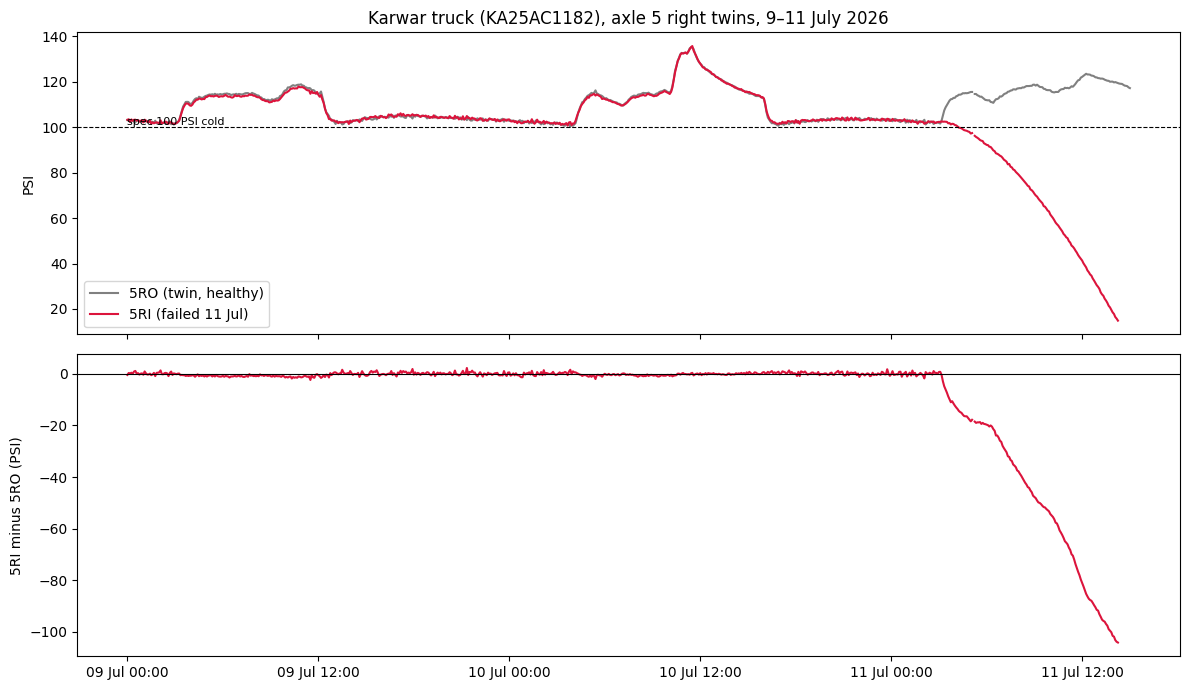

In [7]:
# Section 4 — Karwar 5RI failure: was there any warning before 11 July?
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 4a. Put the failed tyre (5RI) and its twin (5RO) side by side.
#     Twins share the same hub, load, speed, road and weather, so the difference between them
#     removes everything except a problem with one tyre.
k = tyre[(tyre.truck == 'KA25AC1182') & (tyre.pos.isin(['5RI', '5RO']))]
tw = k.pivot_table(index='Time', columns='pos', values=['PSI', 'TEMP'])
tw.columns = [f'{a}_{b}' for a, b in tw.columns]
tw['dPSI'] = tw['PSI_5RI'] - tw['PSI_5RO']        # negative = failed tyre lower than its twin
tw['dTEMP'] = tw['TEMP_5RI'] - tw['TEMP_5RO']

# 4b. What is "normal" for this pair? Use everything up to the end of 9 July.
base = tw.loc[:'2026-07-09', 'dPSI']
print('Normal 5RI minus 5RO difference, 1 Jun – 9 Jul:')
print(f'  median {base.median():.1f} PSI | middle 95% from {base.quantile(.025):.1f} to {base.quantile(.975):.1f} PSI | '
      f'most extreme {base.min():.1f} to {base.max():.1f} PSI')

# 4c. Daily view: largest gap between the twins on each day from 1 July
#     (10-minute medians smooth out single noisy readings)
sm = tw[['PSI_5RI', 'PSI_5RO', 'dPSI', 'dTEMP']].resample('10min').median()
daily = sm.loc['2026-07-01':'2026-07-11'].groupby(sm.loc['2026-07-01':'2026-07-11'].index.date).agg(
    min_dPSI=('dPSI', 'min'), max_dPSI=('dPSI', 'max'), min_5RI_psi=('PSI_5RI', 'min'))
print('\nDaily range of the twin difference (10-min medians):')
print(daily.round(1).to_string())

# 4d. Hour by hour from the evening of 10 July to the failure
print('\nHourly medians, 10 Jul 18:00 – 11 Jul 15:00:')
print(tw.loc['2026-07-10 18:00':'2026-07-11 15:00', ['PSI_5RI', 'PSI_5RO', 'dPSI', 'TEMP_5RI', 'TEMP_5RO', 'dTEMP']]
        .resample('1h').median().round(1).to_string())

# 4e. When would simple twin-difference alarms have fired?
for thr in [-5, -10, -20]:
    hit = sm.loc[sm['dPSI'] < thr]
    first = hit.index.min()
    print(f'First 10-min period with 5RI more than {abs(thr)} PSI below its twin: {first}')
print('Last 5RI reading before the sensor went silent:', k.dropna(subset=['PSI']).query("pos=='5RI' and Time < '2026-07-12'").Time.max())

# 4f. Chart: 9–11 July, pressures of both twins and the difference
p = tw.loc['2026-07-09':'2026-07-11 15:00'].resample('5min').median()
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(p.index, p['PSI_5RO'], label='5RO (twin, healthy)', color='grey')
ax[0].plot(p.index, p['PSI_5RI'], label='5RI (failed 11 Jul)', color='crimson')
ax[0].axhline(100, ls='--', lw=0.8, color='black'); ax[0].text(p.index[0], 101, 'spec 100 PSI cold', fontsize=8)
ax[0].set_ylabel('PSI'); ax[0].legend(loc='lower left'); ax[0].set_title('Karwar truck (KA25AC1182), axle 5 right twins, 9–11 July 2026')
ax[1].plot(p.index, p['dPSI'], color='crimson')
ax[1].axhline(0, lw=0.8, color='black')
ax[1].set_ylabel('5RI minus 5RO (PSI)')
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b %H:%M'))
plt.tight_layout(); plt.savefig(DATA + 'fig_karwar_5RI.png', dpi=120); plt.show()

In [8]:
# 4g. Sensor health of 5RI vs 5RO: packet loss before the failure, and battery trend
before = k[(k.pos == '5RI') & (k.Time >= '2026-07-11') & (k.Time <= '2026-07-11 14:19:41')]
print(f'5RI packets missing on 11 Jul, midnight to last reading (14:19:41): {before.PSI.isna().mean()*100:.1f}%')
bt = k.groupby([k.Time.dt.date, 'pos'])['BATT'].median().unstack()
print('\nSensor battery (%), daily median, selected days:')
print(bt.loc[[pd.Timestamp(x).date() for x in ['2026-06-01','2026-06-15','2026-07-01','2026-07-10','2026-07-11','2026-07-12','2026-07-15']]].to_string())

5RI packets missing on 11 Jul, midnight to last reading (14:19:41): 2.0%

Sensor battery (%), daily median, selected days:
pos          5RI   5RO
Time                  
2026-06-01  62.0  77.0
2026-06-15  57.0  74.0
2026-07-01  52.0  70.0
2026-07-10  49.0  68.0
2026-07-11  48.0  68.0
2026-07-12  98.0  68.0
2026-07-15  97.0  67.0


## Section 4H – Additional checks on the Karwar analysis (second review)
C1 packet-loss pattern on 11 Jul · C2 battery jump 48% → 98% · C3 paired readings only
C4 individual readings 03:00–04:00 · C5 thresholds restricted to 11 Jul
C6 false-alarm episodes for a twin-difference alarm, all 24 twin pairs · C7 failure time vs last reading
Feeds Assessment Notes: F12, H3, warning rule

In [9]:
# Section 4H — Additional checks on the Karwar 5RI analysis (requested in the second review)
# Uses: tyre, k, tw from Section 4

print('=' * 70); print('C1. 5RI packet loss on 11 Jul, 00:00 to last reading (14:19:41)')
r5 = k[(k.pos == '5RI') & (k.Time >= '2026-07-11') & (k.Time <= '2026-07-11 14:19:41')].sort_values('Time').copy()
r5['miss'] = r5['PSI'].isna()
print(f'Receiver records: {len(r5):,} | 5RI missing: {r5.miss.sum()} ({r5.miss.mean()*100:.1f}%)')
run_id = (r5['miss'] != r5['miss'].shift()).cumsum()
runs = r5[r5.miss].groupby(run_id[r5.miss]).agg(start=('Time', 'min'), end=('Time', 'max'), records=('Time', 'size'))
print(f'Longest run of consecutive missing records: {runs.records.max()} records '
      f'({runs.loc[runs.records.idxmax(), "start"]} to {runs.loc[runs.records.idxmax(), "end"]})')
print('Missing-run lengths (records): ', runs.records.value_counts().sort_index().to_dict())
print('\n% missing by hour:')
print((r5.groupby(r5.Time.dt.hour)['miss'].mean() * 100).round(1).to_string())

print('\n' + '=' * 70); print('C2. 5RI battery around the gap: last readings on 11 Jul, first readings on 12 Jul')
b = k[(k.pos == '5RI') & k.PSI.notna()].sort_values('Time')
print(b[(b.Time <= '2026-07-11 14:19:41')].tail(3)[['Time', 'PSI', 'TEMP', 'BATT']].to_string(index=False))
print(b[(b.Time > '2026-07-11 14:19:41')].head(3)[['Time', 'PSI', 'TEMP', 'BATT']].to_string(index=False))
print('Columns available per slot:', [c for c in df.columns if c.startswith('5RI')], '(no sensor ID or serial in the export)')
pre, post = b[b.Time <= '2026-07-11 14:19:41'].BATT, b[b.Time > '2026-07-11 14:19:41'].BATT
print(f'5RI battery before the gap: {int(pre.min())}–{int(pre.max())}% | after the gap: {int(post.min())}–{int(post.max())}%')
jumps = b.BATT.diff()
print(f'Largest upward battery step anywhere before 11 Jul: {jumps[b.Time < "2026-07-11"].max():.0f} points')

print('\n' + '=' * 70); print('C3. Paired readings: timestamps where both 5RI and 5RO reported')
both = tw[['PSI_5RI', 'PSI_5RO']].notna().all(axis=1)
only_ri = tw.PSI_5RI.notna() & tw.PSI_5RO.isna()
only_ro = tw.PSI_5RO.notna() & tw.PSI_5RI.isna()
print(f'Receiver timestamps: {len(tw):,} | both reported: {both.sum():,} | only 5RI: {only_ri.sum():,} | only 5RO: {only_ro.sum():,}')
paired = tw[both]
base_p = paired.loc[:'2026-07-09', 'dPSI']
print(f'Normal difference (paired only, 1 Jun–9 Jul): median {base_p.median():.1f} | middle 95% {base_p.quantile(.025):.1f} to {base_p.quantile(.975):.1f}')

print('\n' + '=' * 70); print('C4. Individual readings, 11 Jul 02:50–04:00 (every 5th record)')
raw_win = paired.loc['2026-07-11 02:50':'2026-07-11 04:00', ['PSI_5RI', 'PSI_5RO', 'dPSI', 'TEMP_5RI', 'TEMP_5RO']]
print(raw_win.iloc[::5].round(1).to_string())

print('\n' + '=' * 70); print('C5. Threshold crossings restricted to 11 July (paired readings, 10-min medians)')
sm_p = paired[['dPSI']].resample('10min').median()
d11 = sm_p.loc['2026-07-11']
for thr in [-5, -10, -20]:
    print(f'  first 10-min period below {thr} PSI on 11 Jul: {d11[d11.dPSI < thr].index.min()}')

print('\n' + '=' * 70); print('C6. Would a twin-difference alarm have raised false alarms? All 24 twin pairs, 1 Jun – 15 Jul')
#     Paired readings, 10-min median difference; an "episode" is a run of consecutive 10-min periods past the threshold.
pairs = [(f'{ax}{s}I', f'{ax}{s}O') for ax in (4, 5) for s in ('L', 'R')]
rows = []
for truck, g in tyre.groupby('truck'):
    for inner, outer in pairs:
        p = g[g.pos.isin([inner, outer])].pivot_table(index='Time', columns='pos', values='PSI').dropna()
        diff = (p[inner] - p[outer]).resample('10min').median().dropna()
        for thr in [5, 10, 20]:
            flag = diff.abs() > thr
            ep = (flag & ~flag.shift(fill_value=False))
            for s0 in diff.index[ep]:
                rows.append({'truck': truck, 'pair': f'{inner}/{outer}', 'threshold': thr, 'episode_start': s0})
ep = pd.DataFrame(rows)
print('Alarm episodes by threshold (|inner - outer| > threshold):')
print(ep.groupby('threshold').size().to_string())
print('\nEpisodes by truck and twin pair:')
print(ep.pivot_table(index=['truck', 'pair'], columns='threshold', values='episode_start', aggfunc='count', fill_value=0).to_string())
print('\nEvery episode above 10 PSI (date and pair):')
big = ep[ep.threshold >= 10].copy(); big['date'] = big.episode_start.dt.date
print(big.groupby(['truck', 'pair', 'threshold', 'date']).size().rename('episodes').to_string())

print('\n' + '=' * 70); print('C7. Failure time vs last sensor reading')
print('  Last 5RI reading: 2026-07-11 14:19:41 (TPMS)')
print('  Transcript (Ramesh, second-hand from the driver): "By two o\'clock it was finished, shredded, he changed it on the roadside near Kittur"')
print('  Tyre Register: WL-T2-5RI-0242 "removed roadside 11-07-2026"; WL-T2-5RI-0901 fitted 12-07-2026')
print('  First 5RI reading after the gap:', b[b.Time > '2026-07-11 14:19:41'].Time.min())

C1. 5RI packet loss on 11 Jul, 00:00 to last reading (14:19:41)
Receiver records: 2,442 | 5RI missing: 50 (2.0%)
Longest run of consecutive missing records: 1 records (2026-07-11 00:16:40 to 2026-07-11 00:16:40)
Missing-run lengths (records):  {1: 50}

% missing by hour:
Time
0     3.3
1     3.3
2     3.3
3     2.0
4     0.9
5     2.8
6     1.9
7     1.9
8     3.3
9     1.0
10    2.4
11    2.8
12    0.9
13    2.3
14    1.4

C2. 5RI battery around the gap: last readings on 11 Jul, first readings on 12 Jul
               Time  PSI  TEMP  BATT
2026-07-11 14:19:04 14.9  48.2  48.0
2026-07-11 14:19:22 14.2  47.7  48.0
2026-07-11 14:19:41 14.6  49.3  48.0
               Time   PSI  TEMP  BATT
2026-07-12 06:30:21 100.0  23.4  98.0
2026-07-12 06:32:21  99.9  22.7  98.0
2026-07-12 06:34:23 100.0  24.1  98.0
Columns available per slot: ['5RI PSI', '5RI TEMP', '5RI BATT'] (no sensor ID or serial in the export)
5RI battery before the gap: 48–62% | after the gap: 97–98%
Largest upward battery step 

## Section 4I – C6 reworked (alarm episodes on a complete timeline) and C7 (incident chronology)
C6: full 10-min timeline per twin pair, no bins dropped; episode = at least 2 consecutive qualifying bins,
one missing bin tolerated; inner and outer deficits separated; flagged bins and episodes reported separately.
C7: the Karwar truck's stops on 10–12 July from GPS, with 5RI pressure at key moments.
Feeds Assessment Notes: F12, F13, H8, questions for Ramesh, distrust memo

In [10]:
# Section 4I — C6 reworked (alarm episodes on a complete timeline) and C7 (failure chronology)
import numpy as np

# ---------- C6 (revised) ----------
# Rules, stated explicitly:
#  * Each twin pair gets a complete 10-minute timeline from its first to last reading (no bins dropped).
#  * A bin's value is the median inner-minus-outer difference over timestamps where BOTH tyres reported.
#    A bin with no paired reading is "no data".
#  * A bin "qualifies" when the difference is beyond the threshold in a given direction:
#      inner deficit: inner - outer < -threshold     outer deficit: inner - outer > +threshold
#  * An episode is a run of at least 2 consecutive qualifying bins (20 minutes).
#    A single "no data" bin inside a run does not break it; two or more "no data" bins in a row, or any
#    bin with data that does not qualify, end the run. The next qualifying run is a new episode.
#  * Reported: qualifying bins (flagged 10-min periods) and episodes, separately, by direction.
#  * These are historical alarm episodes, not confirmed false alarms.
pairs = [(f'{ax}{s}I', f'{ax}{s}O') for ax in (4, 5) for s in ('L', 'R')]

def episodes(q, nodata, min_bins=2):
    """q, nodata: boolean Series on a complete 10-min index. Returns list of (start, end, n_qualifying_bins)."""
    out, run, gap, start, last = [], 0, 0, None, None
    for t, qi, nd in zip(q.index, q.values, nodata.values):
        if qi:
            if run == 0: start = t
            run += 1; gap = 0; last = t
        elif nd and run > 0 and gap == 0:
            gap = 1                                   # tolerate one missing bin
        else:
            if run >= min_bins: out.append((start, last, run))
            run, gap = 0, 0
    if run >= min_bins: out.append((start, last, run))
    return out

rows, bins_rows = [], []
for truck, g in tyre.groupby('truck'):
    for inner, outer in pairs:
        p = g[g.pos.isin([inner, outer])].pivot_table(index='Time', columns='pos', values='PSI').dropna()
        diff = (p[inner] - p[outer]).resample('10min').median()          # keeps empty bins as NaN
        full = pd.date_range(diff.index.min(), diff.index.max(), freq='10min')
        diff = diff.reindex(full)
        nodata = diff.isna()
        for thr in [5, 10, 20]:
            for direction, q in [('inner deficit', diff < -thr), ('outer deficit', diff > thr)]:
                bins_rows.append({'truck': truck, 'pair': f'{inner}/{outer}', 'threshold': thr, 'direction': direction,
                                  'qualifying_bins': int(q.sum()), 'no_data_bins': int(nodata.sum())})
                for s0, s1, n in episodes(q, nodata):
                    rows.append({'truck': truck, 'pair': f'{inner}/{outer}', 'threshold': thr, 'direction': direction,
                                 'start': s0, 'end': s1 + pd.Timedelta('10min'), 'bins': n})
bins_df, ep = pd.DataFrame(bins_rows), pd.DataFrame(rows)

print('C6. Qualifying 10-min bins and episodes (>= 2 consecutive bins), all 24 twin pairs, 1 Jun – 15 Jul')
summary = (bins_df.groupby(['threshold', 'direction'])['qualifying_bins'].sum().to_frame()
           .join(ep.groupby(['threshold', 'direction']).size().rename('episodes')).fillna(0).astype(int))
print(summary.to_string())
print('\nEpisodes by pair (only pairs with any episode):')
print(ep.pivot_table(index=['truck', 'pair', 'direction'], columns='threshold', values='bins', aggfunc='count', fill_value=0).to_string())
print('\nAll episodes at 10 and 20 PSI:')
e10 = ep[ep.threshold >= 10].copy(); e10['hours'] = ((e10.end - e10.start).dt.total_seconds() / 3600).round(1)
print(e10[['truck', 'pair', 'threshold', 'direction', 'start', 'end', 'hours', 'bins']].sort_values(['threshold', 'start']).to_string(index=False))

# Persistent offset or deterioration? Daily view of the two pairs flagged at 10 PSI besides the failure
def daily_pair(truck, inner, outer, start, end):
    g = tyre[(tyre.truck == truck) & tyre.pos.isin([inner, outer])].pivot_table(index='Time', columns='pos', values='PSI').dropna()
    g = g.loc[start:end]
    return pd.DataFrame({f'{inner} daily min': g[inner].resample('1D').min(), f'{outer} daily min': g[outer].resample('1D').min(),
                         'median diff': (g[inner] - g[outer]).resample('1D').median(),
                         'max |diff|': (g[inner] - g[outer]).abs().resample('1D').max()}).round(1)
print('\nGadag (KA22AD7730) 5RI/5RO, 1–12 June:')
print(daily_pair('KA22AD7730', '5RI', '5RO', '2026-06-01', '2026-06-12').to_string())
print('\nGoa (KA25AB4471) 4LI/4LO, 1–25 June:')
print(daily_pair('KA25AB4471', '4LI', '4LO', '2026-06-01', '2026-06-25').to_string())

# ---------- C7: incident chronology from the truck's own GPS and the TPMS ----------
print('\n' + '=' * 70); print('C7. Karwar truck movements, 10 Jul 20:00 – 12 Jul 08:00 (stationary periods over 30 min)')
mv = df[df.truck == 'KA25AC1182'][['Time', 'GPS Time', 'Latitude', 'Longitude']].sort_values('Time').reset_index(drop=True)
la, lo = np.radians(mv.Latitude), np.radians(mv.Longitude)
a = np.sin((la - la.shift()) / 2) ** 2 + np.cos(la) * np.cos(la.shift()) * np.sin((lo - lo.shift()) / 2) ** 2
mv['km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
mv = mv.set_index('Time').loc['2026-07-10 20:00':'2026-07-12 08:00']
r10 = mv.resample('10min').agg({'km': 'sum', 'Latitude': 'last', 'Longitude': 'last'})
r10['stationary'] = r10.km < 0.05                       # under 50 m in 10 minutes
grp = (r10.stationary != r10.stationary.shift()).cumsum()
stops = r10[r10.stationary].groupby(grp[r10.stationary]).agg(start=('km', lambda x: x.index.min()), end=('km', lambda x: x.index.max()),
                                                              lat=('Latitude', 'last'), lon=('Longitude', 'last'))
stops['end'] = stops['end'] + pd.Timedelta('10min')
stops['minutes'] = ((stops.end - stops.start).dt.total_seconds() / 60).astype(int)
print(stops[stops.minutes >= 30].to_string(index=False))
print('\nFor reference: Karwar is about 14.81 N, 74.13 E; Hubballi about 15.36 N, 75.12 E; Kittur about 15.60 N, 74.78 E; Belagavi about 15.85 N, 74.50 E')

k5 = tyre[(tyre.truck == 'KA25AC1182') & (tyre.pos == '5RI')].dropna(subset=['PSI']).set_index('Time').sort_index()
print('\n5RI pressure at key moments on 11 Jul:')
for ts in ['2026-07-11 03:00', '2026-07-11 06:10', '2026-07-11 09:00', '2026-07-11 12:15', '2026-07-11 14:00', '2026-07-11 14:19']:
    row = k5.loc[:ts].iloc[-1]
    print(f'  {ts}  PSI {row.PSI:5.1f}  TEMP {row.TEMP:4.1f}')

C6. Qualifying 10-min bins and episodes (>= 2 consecutive bins), all 24 twin pairs, 1 Jun – 15 Jul
                         qualifying_bins  episodes
threshold direction                               
5         inner deficit             1796       118
          outer deficit             2632       149
10        inner deficit               65         1
          outer deficit              593        20
20        inner deficit               49         1
          outer deficit                0         0

Episodes by pair (only pairs with any episode):
threshold                          5   10  20
truck      pair    direction                 
KA22AD7730 4RI/4RO inner deficit    1   0   0
           5LI/5LO inner deficit    1   0   0
           5RI/5RO outer deficit   55  20   0
KA22AG3391 5LI/5LO outer deficit   33   0   0
KA25AB4471 4LI/4LO inner deficit  115   0   0
           5RI/5RO outer deficit   61   0   0
KA25AC1182 5RI/5RO inner deficit    1   1   1

All episodes at 10 and 20 PSI

## Section 5 – Cold readings, depot fill practice, and the Hubballi "leaks" (H2)
5a Rest periods: slow-mode runs of at least 3 h with less than 200 m movement
5b Cold reading = each tyre's median over the last 10 min of a rest; morning cold readings vs spec, by truck, depot and axle
5c Fill events: a tyre's pressure steps 3+ PSI between 10-min bins while parked, with temperature steady
5d For each tyre adjusted at a fill: pressure set vs next morning's cold reading
5e Air loss between fills, PSI per 30 days, raw and temperature-adjusted
Feeds Assessment Notes: H2, H8, Methodology (cold-reading definition), transcript claims

In [11]:
# Section 5 — Cold readings, depot fill practice, and the Hubballi "leaks" (H2)
import numpy as np
SPEC = {1: 115, 2: 105, 3: 105, 4: 100, 5: 100}
DEPOT = {'KA25AB4471': 'Belagavi', 'KA25AC1182': 'Belagavi', 'KA22AG3391': 'Belagavi',
         'KA22AD7730': 'Hubballi', 'KA25AE2016': 'Hubballi', 'KA48AF9054': 'Hubballi'}
NAME = {'KA25AB4471': 'T1 Goa', 'KA25AC1182': 'T2 Karwar', 'KA22AD7730': 'T3 Gadag',
        'KA25AE2016': 'T4 City', 'KA48AF9054': 'T5 Shivamogga', 'KA22AG3391': 'T6 Vijayapura'}

w = df.sort_values(['truck', 'Time']).reset_index(drop=True).copy()
w['gap'] = w.groupby('truck')['Time'].diff().dt.total_seconds()
w['slow'] = w['gap'].between(100, 140)

# 5a. Rest periods: runs of consecutive slow-mode records lasting at least 3 hours,
#     with the truck's start and end GPS positions less than 200 m apart (no movement during the rest).
w['run'] = (w['slow'] != w.groupby('truck')['slow'].shift()).cumsum()
runs = w[w.slow].groupby('run').agg(truck=('truck', 'first'), start=('Time', 'min'), end=('Time', 'max'),
                                     lat0=('Latitude', 'first'), lon0=('Longitude', 'first'),
                                     lat1=('Latitude', 'last'), lon1=('Longitude', 'last'))
runs['hours'] = (runs.end - runs.start).dt.total_seconds() / 3600
la0, la1 = np.radians(runs.lat0), np.radians(runs.lat1)
a = np.sin((la1 - la0) / 2) ** 2 + np.cos(la0) * np.cos(la1) * np.sin(np.radians(runs.lon1 - runs.lon0) / 2) ** 2
runs['moved_m'] = 6371000 * 2 * np.arcsin(np.sqrt(a))
rests = runs[(runs.hours >= 3) & (runs.moved_m.fillna(0) < 200)].copy()
print(f'5a. Slow-mode runs: {len(runs):,} | lasting >= 3 h with no movement: {len(rests)}')

# 5b. Cold reading = median of each tyre's readings in the last 10 minutes of a rest (just before the truck moves).
#     Morning cold readings = rests ending between 02:00 and 10:00.
g = {k: v.set_index('Time') for k, v in w.groupby('truck')}
rows = []
for rid, r in rests.iterrows():
    last10 = g[r.truck].loc[r.end - pd.Timedelta('10min'):r.end]
    for s in SLOTS:
        rows.append({'rest': rid, 'truck': r.truck, 'rest_end': r.end, 'hours': r.hours, 'lat': r.lat1, 'lon': r.lon1,
                     'pos': s, 'PSI': last10[f'{s} PSI'].median(), 'TEMP': last10[f'{s} TEMP'].median()})
cold = pd.DataFrame(rows).dropna(subset=['PSI'])
cold['axle'] = cold.pos.str[0].astype(int)
cold['spec'] = cold.axle.map(SPEC)
cold['dev'] = cold.PSI - cold.spec
cold['depot'] = cold.truck.map(DEPOT)
cold['date'] = cold.rest_end.dt.date
morning = cold[cold.rest_end.dt.hour.between(2, 9)].copy()
# exclude the failed Karwar 5RI on 11 Jul and the replacement tyre afterwards
morning = morning[~((morning.truck == 'KA25AC1182') & (morning.pos == '5RI') & (morning.rest_end >= '2026-07-11'))]

print(f'5b. Morning cold readings: {morning.rest.nunique()} rests, {len(morning):,} tyre readings; '
      f'tyre temperature median {morning.TEMP.median():.1f} °C (5–95%: {morning.TEMP.quantile(.05):.1f}–{morning.TEMP.quantile(.95):.1f})')
tab = morning.groupby(['depot', 'truck']).agg(mornings=('rest', 'nunique'), median_dev=('dev', 'median'),
                                              pct_5plus_under=('dev', lambda x: (x <= -5).mean() * 100),
                                              pct_10plus_under=('dev', lambda x: (x <= -10).mean() * 100)).round(1)
tab.index = [f'{d} | {NAME[t]}' for d, t in tab.index]
print('\nMorning cold pressure minus spec (PSI), by truck:')
print(tab.to_string())
print('\nBy depot and axle (median PSI minus spec):')
print(morning.pivot_table(index='depot', columns='axle', values='dev', aggfunc='median').round(1).to_string())

# 5c. Fill events: a tyre's 10-min median pressure steps by 3 PSI or more between consecutive bins while the truck is parked,
#     with its temperature changing by less than 1.5 °C (so the step is air added or released, not heating or cooling).
ev = []
for tr, gg in g.items():
    b = gg[[f'{s} PSI' for s in SLOTS] + [f'{s} TEMP' for s in SLOTS] + ['Latitude', 'Longitude']].resample('10min').median()
    slow = gg['slow'].resample('10min').mean()
    for s in SLOTS:
        dP, dT = b[f'{s} PSI'].diff(), b[f'{s} TEMP'].diff()
        hit = (dP.abs() >= 3) & (dT.abs() < 1.5) & (slow >= 0.5) & (slow.shift() >= 0.5)
        for t in dP[hit].index:
            ev.append({'truck': tr, 'bin': t, 'pos': s, 'before': b[f'{s} PSI'].shift().loc[t], 'after': b[f'{s} PSI'].loc[t],
                       'temp': b[f'{s} TEMP'].loc[t], 'spec': SPEC[int(s[0])], 'lat': b.Latitude.loc[t], 'lon': b.Longitude.loc[t]})
fills = pd.DataFrame(ev)
fills['change'] = fills.after - fills.before
fills['after_minus_card'] = fills.after - fills.spec
fills['date'] = fills.bin.dt.date
fe = fills.groupby(['truck', 'date']).agg(time=('bin', 'min'), tyres=('pos', 'nunique'),
                                          raised=('change', lambda x: (x > 0).sum()), lowered=('change', lambda x: (x < 0).sum()),
                                          tyre_temp=('temp', 'median'), after_minus_card=('after_minus_card', 'median'),
                                          lat=('lat', 'median'), lon=('lon', 'median')).reset_index()
fe['depot'] = fe.truck.map(DEPOT); fe['truck'] = fe.truck.map(NAME)
fe['time'] = fe.time.dt.strftime('%H:%M')
print('\n5c. Fill events (tyres whose pressure stepped while parked):')
print(fe[['depot', 'truck', 'date', 'time', 'tyres', 'raised', 'lowered', 'tyre_temp', 'after_minus_card', 'lat', 'lon']].round(2).to_string(index=False))

# 5d. For every tyre adjusted in a fill: pressure set at the fill vs its next morning cold reading
nxt = []
for _, f in fills.iterrows():
    m = morning[(morning.truck == f.truck) & (morning.pos == f.pos) & (morning.rest_end > f.bin)].sort_values('rest_end').head(1)
    if len(m):
        nxt.append({'depot': DEPOT[f.truck], 'truck': NAME[f.truck], 'pos': f.pos, 'fill_temp': f.temp, 'set_minus_card': f.after_minus_card,
                    'next_morning_temp': m.TEMP.iloc[0], 'next_morning_minus_card': m.dev.iloc[0]})
nxt = pd.DataFrame(nxt)
print('\n5d. Tyres adjusted at a fill: set pressure vs next morning cold reading (median by depot):')
print(nxt.groupby('depot')[['fill_temp', 'set_minus_card', 'next_morning_temp', 'next_morning_minus_card']].median().round(1).to_string())
print(f'   tyres: Belagavi {(nxt.depot=="Belagavi").sum()}, Hubballi {(nxt.depot=="Hubballi").sum()}')

# 5e. Air loss between fills: slope of each tyre's morning cold pressure over days, within each interval between fills
#     (at least 5 mornings). Goa axle 3 is split at the 28 June swap. Reported as PSI per 30 days (spec allows about 3).
fill_dates = fills.groupby('truck')['bin'].apply(lambda x: sorted(set(x.dt.normalize())))
sl = []
for (tr, pos), m in morning.groupby(['truck', 'pos']):
    cuts = list(fill_dates.get(tr, []))
    if tr == 'KA25AB4471' and pos in ('3LO', '3RO'): cuts.append(pd.Timestamp('2026-06-28'))
    cuts = sorted(set(cuts)) + [pd.Timestamp('2100-01-01')]
    lo = pd.Timestamp('2000-01-01')
    for hi in cuts:
        seg = m[(m.rest_end > lo) & (m.rest_end <= hi)]
        if len(seg) >= 5:
            days = (seg.rest_end - seg.rest_end.min()).dt.total_seconds() / 86400
            slope = np.polyfit(days, seg.PSI, 1)[0] * 30
            # temperature-adjusted slope: PSI = a + b*days + c*TEMP (removes small differences in morning temperature)
            X = np.column_stack([np.ones(len(seg)), days, seg.TEMP.values])
            coef = np.linalg.lstsq(X, seg.PSI.values, rcond=None)[0]
            sl.append({'depot': DEPOT[tr], 'truck': NAME[tr], 'pos': pos, 'mornings': len(seg), 'psi_per_30d': slope,
                       'psi_per_30d_temp_adj': coef[1] * 30, 'psi_per_degC': coef[2],
                       'start': seg.rest_end.min().date(), 'temp_range': seg.TEMP.max() - seg.TEMP.min()})
        lo = hi
sl = pd.DataFrame(sl)
print('\n5e. Morning cold pressure change between fills (PSI per 30 days; negative = losing air):')
for col in ['psi_per_30d', 'psi_per_30d_temp_adj']:
    print(f'\n{col}:')
    print(sl.groupby('depot')[col].describe(percentiles=[.25, .5, .75]).round(1).to_string())
print(f"\nPressure change per °C of morning tyre temperature (median of fits): {sl.psi_per_degC.median():.2f} PSI/°C")
print('\nBy truck (median, temperature-adjusted):')
print(sl.groupby(['depot', 'truck'])['psi_per_30d_temp_adj'].median().round(1).to_string())
print('\nTyre intervals losing more than 6 PSI per 30 days after temperature adjustment:')
fast = sl[sl.psi_per_30d_temp_adj < -6].sort_values('psi_per_30d_temp_adj')
print(fast[['depot', 'truck', 'pos', 'start', 'mornings', 'psi_per_30d', 'psi_per_30d_temp_adj']].round(1).to_string(index=False))

5a. Slow-mode runs: 373 | lasting >= 3 h with no movement: 292
5b. Morning cold readings: 219 rests, 3,062 tyre readings; tyre temperature median 24.8 °C (5–95%: 23.0–28.4)

Morning cold pressure minus spec (PSI), by truck:
                          mornings  median_dev  pct_5plus_under  pct_10plus_under
Belagavi | T6 Vijayapura        39        -1.2              4.4               0.0
Belagavi | T1 Goa               23        -1.7             16.5               0.6
Belagavi | T2 Karwar            39        -0.8              0.0               0.0
Hubballi | T3 Gadag             39       -12.4             99.8              82.2
Hubballi | T4 City              39       -10.0             99.6              50.7
Hubballi | T5 Shivamogga        40       -10.6             99.6              63.0

By depot and axle (median PSI minus spec):
axle         1     2     3     4     5
depot                                 
Belagavi  -1.1  -0.8  -1.6  -1.3  -1.0
Hubballi -10.1 -10.4 -10.1 -11.1 -12.0

5

## Section 5B – Corrections and checks from the Section 5 review
R1 Rest periods: cumulative GPS distance through each rest (before/after counts)
R2 Depot comparison repeated on rests that pass R1
R3 Every detected pressure-adjustment event, tyre by tyre, with next-morning cold pressure
R4 Between-fill loss rates re-segmented per tyre at the actual fill timestamp; stability diagnostics per interval
R5 Leak candidates: tyres with repeated fast loss in stable intervals
Feeds Assessment Notes: H2, H8, Methodology

In [12]:
# Section 5B — Corrections and checks requested in the Section 5 review
# Uses: w, runs, rests, g, cold, morning, fills from Section 5

# R1. Rest-period definition: cumulative GPS distance through each qualifying run, not just first-to-last fix
cum = []
for rid, r in rests.iterrows():
    seg = g[r.truck].loc[r.start:r.end, ['Latitude', 'Longitude']].dropna()
    la, lo = np.radians(seg.Latitude.values), np.radians(seg.Longitude.values)
    if len(seg) > 1:
        a = np.sin(np.diff(la) / 2) ** 2 + np.cos(la[:-1]) * np.cos(la[1:]) * np.sin(np.diff(lo) / 2) ** 2
        cum.append(6371000 * 2 * np.arcsin(np.sqrt(a)).sum())
    else:
        cum.append(np.nan)
rests['cum_m'] = cum
print('R1. Rest periods (>= 3 h slow mode, first-to-last fix < 200 m):', len(rests))
print('    cumulative GPS distance within the rest (m):', rests.cum_m.describe(percentiles=[.5, .95, .99]).round(1).to_dict())
for lim in [50, 200, 500]:
    print(f'    rests with cumulative distance < {lim} m: {(rests.cum_m < lim).sum()} of {len(rests)}')
print('    rests with no GPS fix at all:', rests.cum_m.isna().sum())
stationary_ids = rests.index[rests.cum_m.fillna(0) < 200]
morning2 = morning[morning.rest.isin(stationary_ids)].copy()
print(f'    morning cold readings kept after the cumulative check: {morning2.rest.nunique()} rests (was {morning.rest.nunique()})')

# R2. Depot comparison repeated on the rests that pass the cumulative check
tab2 = morning2.groupby(['depot', 'truck']).agg(mornings=('rest', 'nunique'), median_dev=('dev', 'median'),
                                                pct_10plus_under=('dev', lambda x: (x <= -10).mean() * 100)).round(1)
tab2.index = [f'{d} | {NAME[t]}' for d, t in tab2.index]
print('\nR2. Morning cold pressure minus spec, rests passing the cumulative check:')
print(tab2.to_string())

# R3. Detected pressure-adjustment events, tyre by tyre (not confirmed physical inflation events)
f = fills.sort_values(['truck', 'bin', 'pos']).copy()
f['truck_name'] = f.truck.map(NAME); f['depot'] = f.truck.map(DEPOT)
nm = []
for _, x in f.iterrows():
    m = morning2[(morning2.truck == x.truck) & (morning2.pos == x.pos) & (morning2.rest_end > x.bin)].sort_values('rest_end').head(1)
    nm.append(m.dev.iloc[0] if len(m) else np.nan)
f['next_morning_minus_spec'] = nm
f['before_minus_spec'] = f.before - f.spec
print('\nR3. Every detected pressure-adjustment, tyre level:')
print(f[['depot', 'truck_name', 'bin', 'pos', 'temp', 'before_minus_spec', 'change', 'after_minus_card', 'next_morning_minus_spec']]
      .round(1).to_string(index=False))
print('\n    Next morning minus spec, tyre level, by depot:')
print(f.groupby('depot')['next_morning_minus_spec'].describe(percentiles=[.1, .5, .9]).round(1).to_string())
print('    Hubballi tyres adjusted at a fill whose next morning was within 5 PSI of spec:',
      int(((f.depot == 'Hubballi') & (f.next_morning_minus_spec > -5)).sum()), 'of', int((f.depot == 'Hubballi').sum()))

# R4. Between-fill loss rates, segmented per TYRE at the actual fill TIMESTAMP (plus the Goa axle-3 swap)
fill_times = f.groupby(['truck', 'pos'])['bin'].apply(lambda x: sorted(x.tolist()))
rows = []
for (tr, pos), m in morning2.groupby(['truck', 'pos']):
    m = m.sort_values('rest_end')
    cuts = list(fill_times.get((tr, pos), []))
    if tr == 'KA25AB4471' and pos in ('3LO', '3RO'): cuts.append(pd.Timestamp('2026-06-28 12:00'))
    edges = [pd.Timestamp('2000-01-01')] + sorted(cuts) + [pd.Timestamp('2100-01-01')]
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        seg = m[(m.rest_end > lo_) & (m.rest_end < hi_)]
        if len(seg) < 5: continue
        days = (seg.rest_end - seg.rest_end.min()).dt.total_seconds().values / 86400
        temp = seg.TEMP.values
        raw = np.polyfit(days, seg.PSI.values, 1)[0] * 30
        X = np.column_stack([np.ones(len(seg)), days, temp])
        coef = np.linalg.lstsq(X, seg.PSI.values, rcond=None)[0]
        corr = np.corrcoef(days, temp)[0, 1] if temp.std() > 0 else np.nan
        rows.append({'depot': DEPOT[tr], 'truck': NAME[tr], 'pos': pos, 'start': seg.rest_end.min().date(), 'end': seg.rest_end.max().date(),
                     'n': len(seg), 'span_days': round(days.max(), 1), 'raw_30d': raw, 'adj_30d': coef[1] * 30,
                     'psi_per_C': coef[2], 'corr_time_temp': corr})
iv = pd.DataFrame(rows)
# stability flags
iv['unstable'] = ((iv.n < 8) | (iv.span_days < 7) | (iv.corr_time_temp.abs() > 0.7) |
                  (~iv.psi_per_C.between(0.2, 1.2)) | ((iv.adj_30d - iv.raw_30d).abs() > 8))
print(f'\nR4. Between-fill intervals per tyre: {len(iv)} | flagged unstable: {iv.unstable.sum()}')
print('    reasons: n<8:', (iv.n < 8).sum(), '| span<7 d:', (iv.span_days < 7).sum(), '| |corr(time,temp)|>0.7:', (iv.corr_time_temp.abs() > 0.7).sum(),
      '| PSI/°C outside 0.2–1.2:', (~iv.psi_per_C.between(0.2, 1.2)).sum(), '| raw and adjusted differ by >8:', ((iv.adj_30d - iv.raw_30d).abs() > 8).sum())
st = iv[~iv.unstable]
print('\n    Stable intervals, PSI per 30 days by depot:')
print(st.groupby('depot')[['raw_30d', 'adj_30d']].describe(percentiles=[.25, .5, .75]).round(1).T.to_string())
print('\n    Stable intervals, median by truck:')
print(st.groupby(['depot', 'truck'])[['raw_30d', 'adj_30d']].median().round(1).to_string())

# R5. Leak candidates: tyres with at least two STABLE intervals losing more than 6 PSI per 30 days (raw AND adjusted)
st = st.assign(fast=(st.raw_30d < -6) & (st.adj_30d < -6))
cand = st.groupby(['depot', 'truck', 'pos']).agg(stable_intervals=('n', 'size'), fast_intervals=('fast', 'sum'),
                                                 median_adj_30d=('adj_30d', 'median')).reset_index()
print('\nR5. Tyres with at least one stable interval losing > 6 PSI/30 d (raw and adjusted):')
print(cand[cand.fast_intervals >= 1].sort_values(['fast_intervals', 'median_adj_30d'], ascending=[False, True]).round(1).to_string(index=False))
print('\n    Every interval for those tyres:')
keys = cand[cand.fast_intervals >= 1][['truck', 'pos']]
print(iv.merge(keys, on=['truck', 'pos']).sort_values(['truck', 'pos', 'start'])
        [['truck', 'pos', 'start', 'end', 'n', 'span_days', 'raw_30d', 'adj_30d', 'psi_per_C', 'corr_time_temp', 'unstable']].round(2).to_string(index=False))

R1. Rest periods (>= 3 h slow mode, first-to-last fix < 200 m): 292
    cumulative GPS distance within the rest (m): {'count': 292.0, 'mean': 2.6, 'std': 22.3, 'min': 0.0, '50%': 0.0, '95%': 0.0, '99%': 183.4, 'max': 196.1}
    rests with cumulative distance < 50 m: 288 of 292
    rests with cumulative distance < 200 m: 292 of 292
    rests with cumulative distance < 500 m: 292 of 292
    rests with no GPS fix at all: 0
    morning cold readings kept after the cumulative check: 219 rests (was 219)

R2. Morning cold pressure minus spec, rests passing the cumulative check:
                          mornings  median_dev  pct_10plus_under
Belagavi | T6 Vijayapura        39        -1.2               0.0
Belagavi | T1 Goa               23        -1.7               0.6
Belagavi | T2 Karwar            39        -0.8               0.0
Hubballi | T3 Gadag             39       -12.4              82.2
Hubballi | T4 City              39       -10.0              50.7
Hubballi | T5 Shivamogga        

## Section 5C – Adjustment rows vs distinct tyres; how much of the next-morning deficit cooling accounts for
Q1 Adjustment rows, sessions and distinct tyres by depot; outcome for every tyre adjusted more than once
Q2 Next-morning deficit vs the part expected from cooling alone, using the empirical 0.62 PSI/°C, with sensitivity
Feeds Assessment Notes: H2, F14–F16

In [17]:
# Section 5C — Adjustment events vs distinct tyres, and how much of the next-morning deficit temperature accounts for
# Uses: f (tyre-level adjustment rows from 5B), morning2

# Q1. Events vs distinct tyres
nt = []
for _, x in f.iterrows():
    m = morning2[(morning2.truck == x.truck) & (morning2.pos == x.pos) & (morning2.rest_end > x.bin)].sort_values('rest_end').head(1)
    nt.append(m.TEMP.iloc[0] if len(m) else np.nan)
f['next_morning_temp'] = nt
f['session'] = f.truck + ' ' + f.bin.dt.date.astype(str)
f['tyre'] = f.truck_name + ' ' + f.pos
f['under5_next'] = f.next_morning_minus_spec <= -5
print('Q1. Adjustment rows, sessions and distinct tyres by depot')
q1 = f.groupby('depot').agg(adjustment_rows=('pos', 'size'), sessions=('session', 'nunique'), distinct_tyres=('tyre', 'nunique'),
                            rows_5plus_under_next_morning=('under5_next', 'sum'))
q1['distinct_tyres_5plus_under_at_least_once'] = f[f.under5_next].groupby('depot')['tyre'].nunique()
print(q1.fillna(0).astype(int).to_string())

per_tyre = f.groupby(['depot', 'tyre']).agg(times_adjusted=('pos', 'size'),
                                             times_5plus_under_next=('under5_next', 'sum'),
                                             next_morning_range=('next_morning_minus_spec', lambda x: f'{x.min():.1f} to {x.max():.1f}')).reset_index()
print('\nDistinct tyres adjusted more than once: outcome each time')
rep = per_tyre[per_tyre.times_adjusted > 1].sort_values(['depot', 'tyre'])
print(rep.to_string(index=False))
print('\nSummary of repeat-adjusted tyres:')
summ = pd.DataFrame({
    'tyres_adjusted_more_than_once': rep.groupby('depot').size(),
    'at_least_5_under_after_every_adjustment': rep[rep.times_5plus_under_next == rep.times_adjusted].groupby('depot').size(),
    'never_5plus_under': rep[rep.times_5plus_under_next == 0].groupby('depot').size()}).fillna(0).astype(int)
print(summ.to_string())

# Q2. How much of the next-morning deficit does cooling account for?
#     Each row pairs ONE adjustment (its post-adjustment pressure and temperature) with that same tyre's FIRST
#     qualifying morning rest after the adjustment (its pressure and temperature). Complete cases only.
#     Empirical relationship in this dataset only: about 0.62 PSI per °C (median of the 5e fits). Not a universal factor.
K = 0.62
need = ['after_minus_card', 'temp', 'next_morning_minus_spec', 'next_morning_temp']
cc = f.dropna(subset=need)
print(f'\nQ2. Complete cases: {len(cc)} of {len(f)} adjustment rows have post-adjustment pressure, adjustment temperature, '
      f'next-morning pressure and next-morning temperature (Belagavi {(cc.depot=="Belagavi").sum()}, Hubballi {(cc.depot=="Hubballi").sum()})')
# pairing check: the next-morning rest used is the first qualifying morning rest after the adjustment, for the same truck and tyre
chk = []
for _, x in cc.iterrows():
    m = morning2[(morning2.truck == x.truck) & (morning2.pos == x.pos) & (morning2.rest_end > x.bin)].sort_values('rest_end').iloc[0]
    chk.append((m.dev == x.next_morning_minus_spec) and (m.TEMP == x.next_morning_temp) and (m.rest_end > x.bin))
print(f'    rows where pressure and temperature both come from the same first subsequent morning rest: {sum(chk)} of {len(cc)}')
f = cc.copy()
f['cooling_C'] = f.temp - f.next_morning_temp
f['expected_from_cooling'] = f.after_minus_card - K * f.cooling_C
f['residual'] = f.next_morning_minus_spec - f.expected_from_cooling
print('\nQ2. Pressure at the first subsequent qualifying morning-rest reading vs the part expected from cooling alone '
      '(medians, PSI; 0.62 PSI/°C is the empirical coefficient from this dataset).')
print('Each column is a separate median across rows, so the columns need not add up exactly.')
print('Hubballi: all matched readings are the following morning (14–16 h after adjustment). '
      'Belagavi: 28 of 43 are departure readings a median 0.6 h after adjustment, so its row shows adjustment-to-departure change, '
      'not overnight cooling. Fair depot comparison: Section 5D (first morning reading at least 12 h later).')
print(f.groupby('depot')[['after_minus_card', 'cooling_C', 'expected_from_cooling', 'next_morning_minus_spec', 'residual']]
        .median().round(1).to_string())
print('\nSensitivity of the Hubballi residual to the PSI/°C value:')
for k in [0.4, 0.5, 0.62, 0.7, 0.8]:
    h = f[f.depot == 'Hubballi']
    print(f'  {k:.2f} PSI/°C -> expected {(h.after_minus_card - k * h.cooling_C).median():6.1f} | '
          f'observed {h.next_morning_minus_spec.median():6.1f} | residual {(h.next_morning_minus_spec - (h.after_minus_card - k * h.cooling_C)).median():5.1f}')

Q1. Adjustment rows, sessions and distinct tyres by depot
          adjustment_rows  sessions  distinct_tyres  rows_5plus_under_next_morning  distinct_tyres_5plus_under_at_least_once
depot                                                                                                                       
Belagavi               43         7              37                              0                                         0
Hubballi               69         9              38                             69                                        38

Distinct tyres adjusted more than once: outcome each time
   depot              tyre  times_adjusted  times_5plus_under_next next_morning_range
Belagavi        T1 Goa 4LI               3                       0        -0.2 to 0.8
Belagavi     T2 Karwar 3LO               2                       0       -0.3 to -0.1
Belagavi     T2 Karwar 4RI               2                       0         0.1 to 2.1
Belagavi     T2 Karwar 5LI             

## Section 5D – Timing check on the "next morning" match
Elapsed time and calendar days from each detected pressure-adjustment event to its matched morning reading;
sensitivity using the first morning reading at least 12 h after the adjustment.

In [16]:
# Section 5D — Timing check: how soon after each adjustment is the "next morning" reading?
# Uses: f (complete-case adjustment rows from 5C), morning2
tm = []
for _, x in f.iterrows():
    m = morning2[(morning2.truck == x.truck) & (morning2.pos == x.pos) & (morning2.rest_end > x.bin)].sort_values('rest_end').iloc[0]
    tm.append(m.rest_end)
f['morning_rest_end'] = tm
f['elapsed_h'] = (f.morning_rest_end - f.bin).dt.total_seconds() / 3600
f['days_later'] = (f.morning_rest_end.dt.normalize() - f.bin.dt.normalize()).dt.days
print('Elapsed hours from adjustment to the matched morning reading, by depot:')
print(f.groupby('depot')['elapsed_h'].agg(['count', 'min', 'median', 'max']).round(1).to_string())
print('\nCalendar days between adjustment and matched morning reading:')
print(f.groupby(['depot', 'days_later']).size().unstack(fill_value=0).to_string())
print('\nRows where the matched morning is 2 or more calendar days later:')
late = f[f.days_later >= 2]
print(late[['depot', 'truck_name', 'pos', 'bin', 'morning_rest_end', 'elapsed_h', 'next_morning_minus_spec']].round(1).to_string(index=False) if len(late) else 'none')

# Sensitivity: match each adjustment to the first qualifying morning rest that ends at least 12 hours later
# (so Belagavi rows are compared with the following day's morning, like Hubballi's)
nd = []
for _, x in f.iterrows():
    m = morning2[(morning2.truck == x.truck) & (morning2.pos == x.pos) & (morning2.rest_end > x.bin + pd.Timedelta('12h'))].sort_values('rest_end').head(1)
    nd.append((m.dev.iloc[0], m.TEMP.iloc[0], (m.rest_end.iloc[0] - x.bin).total_seconds() / 3600) if len(m) else (np.nan, np.nan, np.nan))
f[['dev_12h', 'temp_12h', 'elapsed_12h']] = pd.DataFrame(nd, index=f.index)
print('\nSensitivity: first morning reading at least 12 h after the adjustment')
print(f.groupby('depot').agg(rows=('dev_12h', 'count'), elapsed_min=('elapsed_12h', 'min'), elapsed_median=('elapsed_12h', 'median'),
                             elapsed_max=('elapsed_12h', 'max'), median_minus_spec=('dev_12h', 'median'),
                             min_minus_spec=('dev_12h', 'min'), max_minus_spec=('dev_12h', 'max'),
                             rows_5plus_under=('dev_12h', lambda x: (x <= -5).sum())).round(1).to_string())

Elapsed hours from adjustment to the matched morning reading, by depot:
          count   min  median   max
depot                              
Belagavi     43   0.2     0.6  21.8
Hubballi     69  14.4    14.9  16.3

Calendar days between adjustment and matched morning reading:
days_later   0   1
depot             
Belagavi    28  15
Hubballi     0  69

Rows where the matched morning is 2 or more calendar days later:
none

Sensitivity: first morning reading at least 12 h after the adjustment
          rows  elapsed_min  elapsed_median  elapsed_max  median_minus_spec  min_minus_spec  max_minus_spec  rows_5plus_under
depot                                                                                                                        
Belagavi    43         21.5            23.5         72.5                0.3            -1.9             2.4                 0
Hubballi    69         14.4            14.9         16.3              -10.7           -17.9            -5.8                69

## Section 6 – The Goa truck's afternoon "all fourteen tyres" alarms (H1)
6a 10-min medians per truck · 6b Common cooling events: median tyre temp −8 °C or more and 12+ tyres losing 3+ PSI within 30 min, engine on
6c Goa trip days with and without events · 6d One event tyre by tyre · 6f Fleet context (where, when, which trucks, GPS)
6g Would the twin-difference rule have fired? · 6e Chart: dry trip day vs monsoon trip day
Feeds Assessment Notes: H1, H5, F13 (alarm rule), F6 (GPS)

T3 Gadag: qualifying bins with engine on at both endpoints only: 16 | in all four bins: 16
T6 Vijayapura: qualifying bins with engine on at both endpoints only: 16 | in all four bins: 16
T1 Goa: qualifying bins with engine on at both endpoints only: 36 | in all four bins: 36
T2 Karwar: qualifying bins with engine on at both endpoints only: 31 | in all four bins: 31
T4 City: qualifying bins with engine on at both endpoints only: 6 | in all four bins: 6
T5 Shivamogga: qualifying bins with engine on at both endpoints only: 7 | in all four bins: 7

6b. Common cooling events (revised windows; engine on in all four bins of the comparison window)
Events by truck:
truck
T1 Goa           13
T2 Karwar        10
T3 Gadag          6
T4 City           4
T5 Shivamogga     3
T6 Vijayapura     7
Events with more than one qualifying bin: 40

Goa truck events:
      date               start                 end  qualifying_bins  window_minutes  temp_drop_C  tyres_dropping  median_psi_drop  psi_per_C  gps

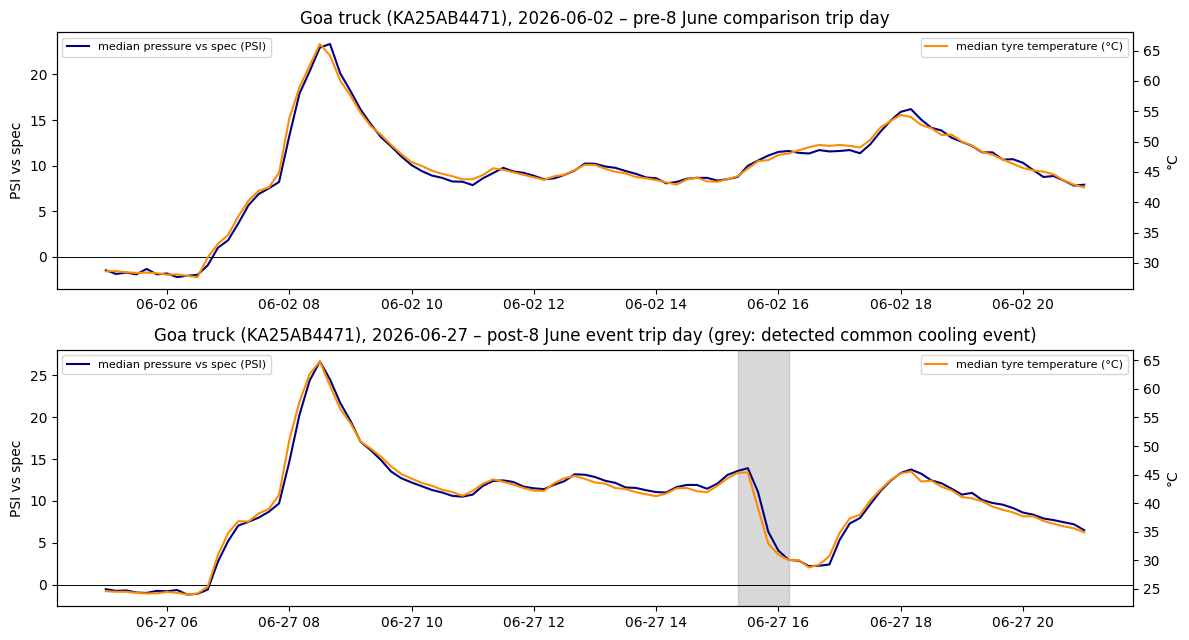

In [25]:
# Section 6 — The Goa truck's afternoon "all fourteen tyres" alarms (H1)
import numpy as np
SPEC = {1: 115, 2: 105, 3: 105, 4: 100, 5: 100}
NAME = {'KA25AB4471': 'T1 Goa', 'KA25AC1182': 'T2 Karwar', 'KA22AD7730': 'T3 Gadag',
        'KA25AE2016': 'T4 City', 'KA48AF9054': 'T5 Shivamogga', 'KA22AG3391': 'T6 Vijayapura'}

# 6a. 10-minute medians per truck: each tyre's pressure and temperature, the median across the 14 tyres,
#     whether the truck was reporting in fast mode, and whether GPS was missing.
bins = {}
for tr, gg in df.sort_values('Time').groupby('truck'):
    gg = gg.set_index('Time')
    gap = gg.index.to_series().diff().dt.total_seconds()
    b = gg[[f'{s} PSI' for s in SLOTS] + [f'{s} TEMP' for s in SLOTS]].astype(float).resample('10min').median()
    b['temp_med'] = b[[f'{s} TEMP' for s in SLOTS]].median(axis=1)
    b['fast'] = (gap < 60).resample('10min').mean() >= 0.5
    b['gps_missing'] = gg['Latitude'].isna().resample('10min').mean()
    b['lat'] = gg['Latitude'].resample('10min').median(); b['lon'] = gg['Longitude'].resample('10min').median()
    bins[tr] = b

# 6b. Common cooling events (revised).
#     Detection: a 10-min bin t qualifies when, comparing bin t with bin t-30 min, the median tyre temperature falls
#     by at least 8 °C AND at least 12 of the 14 tyres each lose at least 3 PSI, AND the truck is in fast mode in all
#     four bins t-30, t-20, t-10 and t (engine on throughout the comparison window, not only at the endpoints).
#     Consecutive qualifying bins are merged into one event.
#     Event window = from (first qualifying bin - 30 min) to the last qualifying bin. All measurements use this window:
#     pressure and temperature change = last bin minus window-start bin; GPS share and location over the whole window.
rows = []
for tr, b in bins.items():
    dT = b.temp_med - b.temp_med.shift(3)
    dPs = pd.concat([b[f'{s} PSI'] - b[f'{s} PSI'].shift(3) for s in SLOTS], axis=1)
    n_drop = (dPs <= -3).sum(axis=1)
    fast = b.fast.astype(bool)
    fast_all4 = fast & fast.shift(1, fill_value=False) & fast.shift(2, fill_value=False) & fast.shift(3, fill_value=False)
    fast_ends = fast & fast.shift(3, fill_value=False)
    hit = (dT <= -8) & (n_drop >= 12) & fast_all4
    hit_ends = (dT <= -8) & (n_drop >= 12) & fast_ends
    ev_id = (hit != hit.shift()).cumsum()
    for _, grp in b[hit].groupby(ev_id[hit]):
        first_bin, last_bin = grp.index.min(), grp.index.max()
        w0 = first_bin - pd.Timedelta('30min')
        P = [f'{s} PSI' for s in SLOTS]; T = [f'{s} TEMP' for s in SLOTS]
        dP_t = b.loc[last_bin, P].to_numpy(dtype=float) - b.loc[w0, P].to_numpy(dtype=float)
        dT_t = b.loc[last_bin, T].to_numpy(dtype=float) - b.loc[w0, T].to_numpy(dtype=float)
        later = b.loc[last_bin + pd.Timedelta('1h'):last_bin + pd.Timedelta('3h')]
        rec = later[later.temp_med >= b.loc[w0, 'temp_med'] - 2].head(1)
        rec_dP = (rec[P].to_numpy(dtype=float)[0] - b.loc[w0, P].to_numpy(dtype=float)) if len(rec) else np.array([np.nan])
        win = b.loc[w0:last_bin]
        rows.append({'truck': NAME[tr], 'window_start': w0, 'first_qualifying_bin': first_bin, 'last_qualifying_bin': last_bin,
                     'qualifying_bins': len(grp), 'window_minutes': int((last_bin - w0).total_seconds() / 60), 'hour': w0.hour,
                     'temp_drop_C': -(b.loc[last_bin, 'temp_med'] - b.loc[w0, 'temp_med']),
                     'tyres_dropping': int(n_drop.loc[grp.index].max()),
                     'median_psi_drop': -np.nanmedian(dP_t), 'psi_per_C': np.nanmedian(dP_t / dT_t),
                     'gps_missing_share': win['gps_missing'].mean(), 'lat': win['lat'].median(), 'lon': win['lon'].median(),
                     'recovery_measured': bool(len(rec) and np.isfinite(rec_dP).any()),
                     'pressure_vs_before_when_temp_back': np.nanmedian(rec_dP) if np.isfinite(rec_dP).any() else np.nan})
    print(f"{NAME[tr]}: qualifying bins with engine on at both endpoints only: {int(hit_ends.sum())} | in all four bins: {int(hit.sum())}")
ev = pd.DataFrame(rows).rename(columns={'window_start': 'start', 'last_qualifying_bin': 'end'})
print('\n6b. Common cooling events (revised windows; engine on in all four bins of the comparison window)')
print('Events by truck:'); print(ev.groupby('truck').size().reindex(list(NAME.values()), fill_value=0).to_string())
print('Events with more than one qualifying bin:', int((ev.qualifying_bins > 1).sum()))

g1 = ev[ev.truck == 'T1 Goa'].copy()
g1['date'] = g1.start.dt.date
print('\nGoa truck events:')
print(g1[['date', 'start', 'end', 'qualifying_bins', 'window_minutes', 'temp_drop_C', 'tyres_dropping', 'median_psi_drop', 'psi_per_C',
          'gps_missing_share', 'lat', 'lon', 'pressure_vs_before_when_temp_back']].round(2).to_string(index=False))
r = g1.pressure_vs_before_when_temp_back
print(f'Recovery (pressure when temperature is back within 2 °C, vs window start): measured for {g1.recovery_measured.sum()} of {len(g1)} events; '
      f'median {r.median():.2f}, range {r.min():.2f} to {r.max():.2f} PSI; above zero in {(r > 0).sum()}, below zero in {(r < 0).sum()}')
print('\nGoa truck events by hour of day:', g1.hour.value_counts().sort_index().to_dict())
print('Goa truck events before / from 8 June:', int((g1.start < '2026-06-08').sum()), '/', int((g1.start >= '2026-06-08').sum()))

# 6c. Goa trip days and how many had an event (trip day = truck went west of 74.2 E, i.e. down towards Goa)
goa = bins['KA25AB4471']
trip_days = sorted(set(goa[goa.lon < 74.2].index.date))
ev_days = set(g1.date)
print(f'\n6c. Goa trip days: {len(trip_days)} | with at least one common cooling event: {len(ev_days & set(trip_days))}')
print('    trip days before 8 June:', [str(d) for d in trip_days if d < pd.Timestamp("2026-06-08").date()],
      '| events on those days:', len([d for d in ev_days if d < pd.Timestamp("2026-06-08").date()]))

# 6d. A tyre-by-tyre view of one event: did every tyre drop together, and by how much per °C?
if len(g1):
    e0 = g1.iloc[len(g1) // 2]
    t0, t1 = e0.start, e0.end
    one = pd.DataFrame({'PSI_before': goa.loc[t0, [f'{s} PSI' for s in SLOTS]].to_numpy(dtype=float),
                        'PSI_after': goa.loc[t1, [f'{s} PSI' for s in SLOTS]].to_numpy(dtype=float),
                        'TEMP_before': goa.loc[t0, [f'{s} TEMP' for s in SLOTS]].to_numpy(dtype=float),
                        'TEMP_after': goa.loc[t1, [f'{s} TEMP' for s in SLOTS]].to_numpy(dtype=float)}, index=SLOTS)
    one['spec'] = [SPEC[int(s[0])] for s in SLOTS]
    one['after_vs_spec'] = one.PSI_after - one.spec
    one['psi_per_C'] = (one.PSI_after - one.PSI_before) / (one.TEMP_after - one.TEMP_before)
    print(f'\n6d. Example event {t0} to {t1}, tyre by tyre:')
    print(one.round(1).to_string())

# 6f. Fleet context: where and when the events happen on the other trucks
inv = {v: k for k, v in NAME.items()}
def speed(tr, t0, t1):
    gg = df[(df.truck == tr) & (df.Time >= t0) & (df.Time <= t1)].dropna(subset=['Latitude'])
    if len(gg) < 2: return np.nan
    la, lo = np.radians(gg.Latitude.values.astype(float)), np.radians(gg.Longitude.values.astype(float))
    a = np.sin(np.diff(la) / 2) ** 2 + np.cos(la[:-1]) * np.cos(la[1:]) * np.sin(np.diff(lo) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a)).sum() / ((gg.Time.max() - gg.Time.min()).total_seconds() / 3600)
ev['kmh'] = [speed(inv[r.truck], r.start, r.end) for r in ev.itertuples()]
base_gps = {NAME[tr]: b.gps_missing.mean() for tr, b in bins.items()}
print('\n6f. All trucks: events, hours, speed during event, GPS missing during events vs overall')
fl = ev.groupby('truck').agg(events=('start', 'size'), first=('start', 'min'), hours=('hour', lambda x: f'{x.min()}-{x.max()}'),
                             median_kmh=('kmh', 'median'), gps_missing_in_events=('gps_missing_share', 'median'),
                             median_psi_drop=('median_psi_drop', 'median'), psi_per_C=('psi_per_C', 'median'))
fl['gps_missing_overall'] = fl.index.map(base_gps)
print(fl.round(2).to_string())
ev['slot'] = ev.start.dt.floor('h')
same = ev.groupby(ev.start.dt.date).agg(trucks=('truck', 'nunique'), which=('truck', lambda x: ', '.join(sorted(set(x)))),
                                         hours=('hour', lambda x: ', '.join(str(h) for h in sorted(set(x)))))
print('\nDays when two or more trucks had an event (same day):')
print(same[same.trucks >= 2].to_string())

# 6h. Karwar events: was the truck actually stationary? Cumulative GPS distance and number of fixes in each event window.
kw = []
for r_ in ev[ev.truck == 'T2 Karwar'].itertuples():
    gg = df[(df.truck == 'KA25AC1182') & (df.Time >= r_.start) & (df.Time <= r_.end + pd.Timedelta('10min'))]
    fx = gg.dropna(subset=['Latitude'])
    if len(fx) > 1:
        la, lo = np.radians(fx.Latitude.values.astype(float)), np.radians(fx.Longitude.values.astype(float))
        a = np.sin(np.diff(la) / 2) ** 2 + np.cos(la[:-1]) * np.cos(la[1:]) * np.sin(np.diff(lo) / 2) ** 2
        dist = 6371000 * 2 * np.arcsin(np.sqrt(a)).sum()
    else:
        dist = np.nan
    kw.append({'start': r_.start, 'records': len(gg), 'gps_fixes': len(fx), 'cum_distance_m': dist,
               'lat_range': fx.Latitude.max() - fx.Latitude.min() if len(fx) else np.nan,
               'lon_range': fx.Longitude.max() - fx.Longitude.min() if len(fx) else np.nan})
print('\n6h. Karwar events: GPS fixes and cumulative distance within each event window')
print(pd.DataFrame(kw).round(5).to_string(index=False))

# 6g. Would the twin-difference rule (F13) have fired during the Goa events? Max |inner - outer| during each event.
tw_rows = []
for _, e in g1.iterrows():
    w_ = goa.loc[e.start:e.end]
    d = max(abs(w_[f'{ax}{sd}I PSI'] - w_[f'{ax}{sd}O PSI']).max() for ax in (4, 5) for sd in ('L', 'R'))
    tw_rows.append(d)
g1['max_twin_diff'] = tw_rows
print('\n6g. Proposed twin-difference rule: largest twin difference (PSI) during each event:', [round(x, 1) for x in g1.max_twin_diff],
      '| any above 10 PSI:', bool((g1.max_twin_diff > 10).any()))
print('    Goa events: lowest tyre pressure vs spec during the event (PSI):',
      [round(min((goa.loc[e.start:e.end, f'{s} PSI'] - SPEC[int(s[0])]).min() for s in SLOTS), 1) for _, e in g1.iterrows()])

# 6e. Chart: Goa truck, median tyre pressure (vs spec) and temperature on a dry trip day and a monsoon trip day
import matplotlib.pyplot as plt
dev = pd.concat([goa[f'{s} PSI'] - SPEC[int(s[0])] for s in SLOTS], axis=1).median(axis=1)
days = [str(trip_days[0])] + ([str(g1.date.iloc[len(g1) // 2])] if len(g1) else [])
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=False)
for i, d in enumerate(days):
    sl = slice(f'{d} 05:00', f'{d} 21:00')
    a = ax[i]; a2 = a.twinx()
    a.plot(dev.loc[sl].index, dev.loc[sl], color='navy', label='median pressure vs spec (PSI)')
    a2.plot(goa.loc[sl].index, goa.loc[sl, 'temp_med'], color='darkorange', label='median tyre temperature (°C)')
    for _, e in g1[g1.date.astype(str) == d].iterrows():
        a.axvspan(e.start, e.end, color='grey', alpha=0.3)
    a.axhline(0, color='black', lw=0.7); a.set_ylabel('PSI vs spec'); a2.set_ylabel('°C')
    a.set_title(f'Goa truck (KA25AB4471), {d}' + (' – post-8 June event trip day (grey: detected common cooling event)' if i else ' – pre-8 June comparison trip day'))
    a.legend(loc='upper left', fontsize=8); a2.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.savefig(DATA + 'fig_goa_afternoon.png', dpi=120); plt.show()

Section 6I — Validation checks

In [26]:
# Section 6I — Validation: tyre counts per qualifying comparison, and Karwar GPS strictly within the event window
# Run after the Section 6 cell (uses bins, ev, df, NAME, SLOTS). Detection rule unchanged.
# 6i. How many tyres met the >=3 PSI drop in each qualifying comparison? (detection rule unchanged)
nd_rows = []
for tr, b in bins.items():
    dT = b.temp_med - b.temp_med.shift(3)
    dPs = pd.concat([b[f'{s} PSI'] - b[f'{s} PSI'].shift(3) for s in SLOTS], axis=1)
    n_drop = (dPs <= -3).sum(axis=1)
    fast = b.fast.astype(bool)
    fast_all4 = fast & fast.shift(1, fill_value=False) & fast.shift(2, fill_value=False) & fast.shift(3, fill_value=False)
    hit = (dT <= -8) & (n_drop >= 12) & fast_all4
    ev_id = (hit != hit.shift()).cumsum()
    for _, grp in b[hit].groupby(ev_id[hit]):
        nd = n_drop.loc[grp.index]
        nd_rows.append({'truck': NAME[tr], 'start': grp.index.min() - pd.Timedelta('30min'), 'qualifying_bins': len(grp),
                        'min_n_drop': int(nd.min()), 'median_n_drop': float(nd.median()), 'max_n_drop': int(nd.max()),
                        'bins_with_all_14': int((nd == 14).sum())})
ndf = pd.DataFrame(nd_rows)
print('6i. Tyres dropping >= 3 PSI per qualifying comparison — Goa events:')
print(ndf[ndf.truck == 'T1 Goa'].drop(columns='truck').to_string(index=False))
print('\nFleet-wide, by truck:')
print(ndf.groupby('truck').agg(events=('start', 'size'), qualifying_bins=('qualifying_bins', 'sum'),
                               min_n_drop=('min_n_drop', 'min'), median_of_event_medians=('median_n_drop', 'median'),
                               max_n_drop=('max_n_drop', 'max'), bins_with_all_14=('bins_with_all_14', 'sum'),
                               events_all_14_in_every_bin=('min_n_drop', lambda x: int((x == 14).sum())),
                               events_all_14_in_at_least_one_bin=('max_n_drop', lambda x: int((x == 14).sum()))).to_string())
print(f'Fleet total: {len(ndf)} events, {ndf.qualifying_bins.sum()} qualifying comparisons, {ndf.bins_with_all_14.sum()} with all 14 tyres; '
      f'events with all 14 in every comparison: {(ndf.min_n_drop == 14).sum()}; lowest count in any comparison: {ndf.min_n_drop.min()}')

# 6h (revised). Karwar events: GPS strictly within the event window (start to end), and window + following 10 min for comparison
kw = []
for r_ in ev[ev.truck == 'T2 Karwar'].itertuples():
    out = {'start': r_.start, 'end': r_.end}
    for lab, t_end in (('in_window', r_.end), ('plus_10min', r_.end + pd.Timedelta('10min'))):
        gg = df[(df.truck == 'KA25AC1182') & (df.Time >= r_.start) & (df.Time <= t_end)]
        fx = gg.dropna(subset=['Latitude'])
        if len(fx) > 1:
            la, lo = np.radians(fx.Latitude.values.astype(float)), np.radians(fx.Longitude.values.astype(float))
            a = np.sin(np.diff(la) / 2) ** 2 + np.cos(la[:-1]) * np.cos(la[1:]) * np.sin(np.diff(lo) / 2) ** 2
            dist = 6371000 * 2 * np.arcsin(np.sqrt(a)).sum()
        else:
            dist = np.nan
        out[f'fixes_{lab}'] = len(fx); out[f'dist_m_{lab}'] = dist
        if lab == 'in_window':
            out['lat_range'] = fx.Latitude.max() - fx.Latitude.min() if len(fx) else np.nan
            out['lon_range'] = fx.Longitude.max() - fx.Longitude.min() if len(fx) else np.nan
    kw.append(out)
print('\n6h (revised). Karwar events: GPS strictly within the event window, and with the following 10 minutes added')
print(pd.DataFrame(kw).round(5).to_string(index=False))

6i. Tyres dropping >= 3 PSI per qualifying comparison — Goa events:
              start  qualifying_bins  min_n_drop  median_n_drop  max_n_drop  bins_with_all_14
2026-06-09 14:20:00                2          14           14.0          14                 2
2026-06-11 16:00:00                3          14           14.0          14                 3
2026-06-13 15:00:00                2          14           14.0          14                 2
2026-06-16 16:10:00                3          14           14.0          14                 3
2026-06-18 14:00:00                3          14           14.0          14                 3
2026-06-23 13:40:00                3          14           14.0          14                 3
2026-06-27 15:20:00                3          14           14.0          14                 3
2026-06-30 16:00:00                3          14           14.0          14                 3
2026-07-02 15:40:00                3          14           14.0          14           

Section 7 — Quick checks: batteries, km log, remaining transcript claims

In [27]:
# Section 7 — Quick checks: sensor batteries, km log against GPS, and the remaining transcript claims
import numpy as np
NAME = {'KA25AB4471': 'T1 Goa', 'KA25AC1182': 'T2 Karwar', 'KA22AD7730': 'T3 Gadag',
        'KA25AE2016': 'T4 City', 'KA48AF9054': 'T5 Shivamogga', 'KA22AG3391': 'T6 Vijayapura'}
d_ = df.sort_values(['truck', 'Time']).copy()
d_['date'] = d_.Time.dt.normalize()

# 7a. Sensor batteries: daily median battery per sensor; level at start and end, lowest, rate of decline, and any jump up (possible sensor change)
bt = []
for tr, gg in d_.groupby('truck'):
    daily = gg.groupby('date')[[f'{s} BATT' for s in SLOTS]].median()
    for s in SLOTS:
        x = daily[f'{s} BATT'].dropna()
        if len(x) < 2: continue
        jumps = x.diff()
        days = (x.index[-1] - x.index[0]).days
        bt.append({'truck': NAME[tr], 'tyre': s, 'first_day': x.iloc[0], 'last_day': x.iloc[-1], 'lowest': x.min(),
                   'decline_per_30d': (x.iloc[0] - x.iloc[-1]) / days * 30 if days else np.nan,
                   'largest_daily_rise': jumps.max(), 'date_of_rise': jumps.idxmax().date() if jumps.max() >= 10 else None})
bt = pd.DataFrame(bt)
print('7a. Sensor batteries (daily medians, %)')
print('Distribution of last-day battery across all 84 sensors:', bt.last_day.describe()[['min', '25%', '50%', '75%', 'max']].round(0).to_dict())
print('Median decline per 30 days:', round(bt.decline_per_30d.median(), 1), '| range', round(bt.decline_per_30d.min(), 1), 'to', round(bt.decline_per_30d.max(), 1))
for thr in (20, 30):
    print(f'Sensors ending below {thr}%:', int((bt.last_day < thr).sum()))
print('\nLowest 8 sensors at the end of the period:')
print(bt.sort_values('last_day').head(8).round(1).to_string(index=False))
print('\nSensors whose daily battery rose by 10 points or more in one day (possible sensor or battery change):')
r10 = bt[bt.largest_daily_rise >= 10]
print(r10.round(1).to_string(index=False) if len(r10) else 'none')
print('\nLast-day battery by truck (median of 14 sensors):', bt.groupby('truck').last_day.median().round(0).to_dict())

# 7b. Daily km log against GPS distance.
#     GPS distance = sum of straight-line distances between consecutive GPS fixes on the same day,
#     ignoring steps that imply more than 120 km/h (position jumps). Straight lines between fixes cut corners and
#     missing fixes shorten the total, so GPS distance is expected to be somewhat BELOW the odometer, more so where GPS is often missing.
km = pd.read_excel(DATA + 'Westline_Daily_KM_Jun-Jul_2026.xlsx', header=2)
km.columns = ['date', 'truck', 'open', 'close', 'km_run']
km['date'] = pd.to_datetime(km['date'], format='%d-%m-%Y')
km = km.sort_values(['truck', 'date'])
km['gap_from_previous_close'] = km.open - km.groupby('truck').close.shift()
km['close_minus_open_vs_km_run'] = (km.close - km.open) - km.km_run
print('\n7b. Km log: rows', len(km), '| trucks', km.truck.nunique(), '| days per truck', km.groupby('truck').size().unique().tolist())
print('Odometer continuity breaks (opening not equal to previous closing):', int((km.gap_from_previous_close.fillna(0) != 0).sum()),
      '| rows where closing minus opening differs from KM Run:', int((km.close_minus_open_vs_km_run != 0).sum()))
brk = km[(km.gap_from_previous_close.fillna(0) != 0) | (km.close_minus_open_vs_km_run != 0)]
if len(brk): print(brk.to_string(index=False))

gd = []
for tr, gg in d_.dropna(subset=['Latitude']).groupby('truck'):
    la, lo = np.radians(gg.Latitude.values.astype(float)), np.radians(gg.Longitude.values.astype(float))
    a = np.sin(np.diff(la) / 2) ** 2 + np.cos(la[:-1]) * np.cos(la[1:]) * np.sin(np.diff(lo) / 2) ** 2
    step = 6371 * 2 * np.arcsin(np.sqrt(a))
    dt_h = np.diff(gg.Time.values).astype('timedelta64[s]').astype(float) / 3600
    ok = (step / np.maximum(dt_h, 1e-6)) <= 120
    s = pd.Series(np.where(ok, step, 0), index=gg.date.values[1:])
    gd.append(pd.DataFrame({'truck': tr, 'date': s.groupby(level=0).sum().index, 'gps_km': s.groupby(level=0).sum().values}))
gd = pd.concat(gd)
miss = d_.groupby(['truck', 'date']).Latitude.apply(lambda x: x.isna().mean()).rename('gps_missing').reset_index()
cmp_ = km.merge(gd, on=['truck', 'date'], how='left').merge(miss, on=['truck', 'date'], how='left')
cmp_['gps_km'] = cmp_.gps_km.fillna(0)
cmp_['ratio'] = cmp_.gps_km / cmp_.km_run.replace(0, np.nan)
cmp_['name'] = cmp_.truck.map(NAME)
print('\nKm log vs GPS distance by truck (whole period):')
summ = cmp_.groupby('name').agg(log_km=('km_run', 'sum'), gps_km=('gps_km', 'sum'), median_daily_ratio=('ratio', 'median'),
                                gps_missing=('gps_missing', 'mean'))
summ['gps_as_share_of_log'] = summ.gps_km / summ.log_km
print(summ.round(2).to_string())
print('\nDays where the two disagree sharply (log km > 20 with GPS under 50% of it, or GPS km > 20 with log under 50% of GPS):')
odd = cmp_[((cmp_.km_run > 20) & (cmp_.gps_km < 0.5 * cmp_.km_run)) | ((cmp_.gps_km > 20) & (cmp_.km_run < 0.5 * cmp_.gps_km))]
print(odd[['name', 'date', 'km_run', 'gps_km', 'gps_missing']].round(2).to_string(index=False) if len(odd) else 'none')

# 7c. "The Goa truck goes down Anmod ... three times a week": Goa trip days (truck west of 74.2 E) per ISO week, and the km log's long days
g = d_[(d_.truck == 'KA25AB4471')].dropna(subset=['Longitude'])
trip = sorted(set(g[g.Longitude < 74.2].date))
tw = pd.Series(1, index=pd.DatetimeIndex(trip)).groupby(pd.DatetimeIndex(trip).isocalendar().week).sum()
print('\n7c. Goa trip days per ISO week (week: days):', tw.to_dict(), '| total', len(trip))
gk = cmp_[cmp_.truck == 'KA25AB4471']
print('    Goa km log: days over 200 km:', int((gk.km_run > 200).sum()), '| typical long day', int(gk[gk.km_run > 200].km_run.median()),
      'km | typical short day', int(gk[gk.km_run <= 200].km_run.median()), 'km')
print('    Long-km days that are GPS trip days:', len(set(gk[gk.km_run > 200].date) & set(trip)), 'of', int((gk.km_run > 200).sum()))
print('    Trip days by weekday:', pd.Series([pd.Timestamp(t).day_name()[:3] for t in trip]).value_counts().to_dict())

# 7d. "The city truck was in the workshop two Sundays for a clutch": City truck on each Sunday
c = d_[d_.truck == 'KA25AE2016'].copy()
c['gap_s'] = c.Time.diff().dt.total_seconds()
sun = []
for day, gg in c[c.Time.dt.dayofweek == 6].groupby('date'):
    fx = gg.dropna(subset=['Latitude'])
    sun.append({'date': day.date(), 'records': len(gg), 'fast_mode_share': (gg.gap_s < 60).mean(),
                'gps_km': float(gd[(gd.truck == 'KA25AE2016') & (gd.date == day)].gps_km.sum()),
                'log_km': int(km[(km.truck == 'KA25AE2016') & (km.date == day)].km_run.sum()),
                'lat': fx.Latitude.median(), 'lon': fx.Longitude.median(),
                'temp_range_C': gg[[f'{s} TEMP' for s in SLOTS]].median(axis=1).agg(lambda x: x.max() - x.min())})
print('\n7d. City truck on Sundays:')
print(pd.DataFrame(sun).round(3).to_string(index=False))
home = c.dropna(subset=['Latitude']).groupby(c.Time.dt.hour == 2)[['Latitude', 'Longitude']].median()
print('    City truck usual night position (02:00 median):', home.loc[True].round(4).to_dict())

# 7e. "The Shivamogga truck did one Mangaluru run in the first week of July": days the truck was near Mangaluru (south of 13.0 N, west of 75.0 E)
s5 = d_[d_.truck == 'KA48AF9054'].dropna(subset=['Latitude'])
coast = s5[(s5.Longitude < 75.0) & (s5.Latitude < 13.0)]
print('\n7e. Shivamogga truck: days with fixes near Mangaluru (south of 13.0 N, west of 75.0 E):', sorted(set(str(x.date()) for x in coast.date)))
if len(coast):
    print('    first and last fix there:', coast.Time.min(), 'to', coast.Time.max(),
          '| southernmost fix:', coast.loc[coast.Latitude.idxmin(), ['Latitude', 'Longitude']].round(3).to_dict())
print('    Shivamogga km log and GPS km, 3 to 7 July:')
w5 = cmp_[(cmp_.truck == 'KA48AF9054') & (cmp_.date >= '2026-07-03') & (cmp_.date <= '2026-07-07')]
print(w5[['date', 'km_run', 'gps_km']].assign(date=w5.date.dt.date).round(0).to_string(index=False))
print('    Shivamogga 2RO sensor: share of records with no 2RO reading, whole period vs from 10 July:',
      round(df[df.truck == 'KA48AF9054']['2RO PSI'].isna().mean(), 3), '/',
      round(df[(df.truck == 'KA48AF9054') & (df.Time >= '2026-07-10')]['2RO PSI'].isna().mean(), 3))

7a. Sensor batteries (daily medians, %)
Distribution of last-day battery across all 84 sensors: {'min': 1.0, '25%': 56.0, '50%': 64.0, '75%': 72.0, 'max': 97.0}
Median decline per 30 days: 8.9 | range -23.9 to 25.2
Sensors ending below 20%: 1
Sensors ending below 30%: 1

Lowest 8 sensors at the end of the period:
        truck tyre  first_day  last_day  lowest  decline_per_30d  largest_daily_rise date_of_rise
T5 Shivamogga  2RO       14.0       1.0     1.0              8.9                 0.0         None
     T3 Gadag  5RO       73.0      44.0    44.0             19.8                 0.0         None
       T1 Goa  4LI       81.0      49.0    49.0             21.8                 0.0         None
    T2 Karwar  3LO       86.0      50.0    50.0             24.5                 0.0         None
      T4 City  4RI       64.0      50.0    50.0              9.5                 0.0         None
    T2 Karwar  3RO       64.0      51.0    51.0              8.9                 0.0         None

“Section 7V — Validation checks

In [28]:
# Section 7V — Validation: engine-status field, and Shivamogga maximum daily km
# 1. Is there an engine or ignition field in the data?
cols = list(df.columns)
hits = [c_ for c_ in cols if any(k in c_.lower() for k in ('engine', 'ignition', 'ign', 'acc', 'motor', 'rpm', 'status'))]
print('Columns in the loaded dataframe:', cols)
print('Columns that look like engine or ignition status:', hits if hits else 'none')
raw_cols = pd.read_csv(sorted(glob.glob(DATA + 'TyreSense_export_*.csv'))[0], nrows=0).columns.tolist()
print('Columns in the raw TyreSense export:', [c_ for c_ in raw_cols if not c_[0].isdigit()], '+ tyre PSI/TEMP/BATT columns')

# 2. Shivamogga truck: maximum daily KM Run over the full km log
k5 = km[km.truck == 'KA48AF9054']
print('\nShivamogga km log days:', len(k5), '| maximum KM Run:', int(k5.km_run.max()), 'on', k5.loc[k5.km_run.idxmax(), 'date'].date())
print('Days with KM Run >= 391:', [str(d.date()) for d in k5[k5.km_run >= 391].date])
print('Next-highest days:'); print(k5.nlargest(4, 'km_run')[['date', 'km_run']].assign(date=lambda x: x.date.dt.date).to_string(index=False))
print('Highest day across the other five trucks:', int(km[km.truck != 'KA48AF9054'].km_run.max()))

Columns in the loaded dataframe: ['Time', 'GPS Time', 'Avg Battery', 'Latitude', 'Longitude', '1LO PSI', '1LO TEMP', '1LO BATT', '1RO PSI', '1RO TEMP', '1RO BATT', '2LO PSI', '2LO TEMP', '2LO BATT', '2RO PSI', '2RO TEMP', '2RO BATT', '3LO PSI', '3LO TEMP', '3LO BATT', '3RO PSI', '3RO TEMP', '3RO BATT', '4LI PSI', '4LI TEMP', '4LI BATT', '4LO PSI', '4LO TEMP', '4LO BATT', '4RI PSI', '4RI TEMP', '4RI BATT', '4RO PSI', '4RO TEMP', '4RO BATT', '5LI PSI', '5LI TEMP', '5LI BATT', '5LO PSI', '5LO TEMP', '5LO BATT', '5RI PSI', '5RI TEMP', '5RI BATT', '5RO PSI', '5RO TEMP', '5RO BATT', 'source_file', 'truck']
Columns that look like engine or ignition status: none
Columns in the raw TyreSense export: ['Time', 'Vehicle', 'GPS Time', 'Avg Battery', 'Latitude', 'Longitude'] + tyre PSI/TEMP/BATT columns

Shivamogga km log days: 45 | maximum KM Run: 391 on 2026-07-06
Days with KM Run >= 391: ['2026-07-06']
Next-highest days:
      date  km_run
2026-07-06     391
2026-06-02     218
2026-06-09     218


In [36]:
import os
import glob

print("DATA folder:", DATA)
print("\nChecking expected files:")

for filename in ["build_html.py", "notes.json"]:
    path = os.path.join(DATA, filename)
    print(f"{filename}: {'FOUND' if os.path.isfile(path) else 'NOT FOUND'}")

print("\nFiles matching build_html:")
print(glob.glob("/content/drive/MyDrive/**/build_html*", recursive=True))

print("\nFiles matching notes:")
print(glob.glob("/content/drive/MyDrive/**/notes*", recursive=True))

DATA folder: /content/drive/MyDrive/Westline_Working/

Checking expected files:
build_html.py: FOUND
notes.json: FOUND

Files matching build_html:
['/content/drive/MyDrive/Westline_Working/build_html.py', '/content/drive/MyDrive/Westline_Working/build_html (1).py']

Files matching notes:
['/content/drive/MyDrive/Westline_Working/notes.json']


In [37]:
import os
import traceback

script_path = os.path.join(DATA, "build_html.py")
notes_path = os.path.join(DATA, "notes.json")
output_path = os.path.join(DATA, "Westline_Findings_Full.html")

print("Script exists:", os.path.isfile(script_path))
print("Notes exist:", os.path.isfile(notes_path))

# Check that the earlier analysis sections have run
for name in ["df", "morning2", "fills"]:
    print(f"{name} available:", name in globals())

try:
    with open(script_path, "r", encoding="utf-8") as f:
        script_code = f.read()

    namespace = {}
    exec(compile(script_code, script_path, "exec"), namespace)

    result = namespace["build"](
        df, morning2, fills, notes_path, output_path
    )

    print("HTML successfully generated:", result)

except Exception:
    traceback.print_exc()

Script exists: True
Notes exist: True
df available: True
morning2 available: True
fills available: True
HTML successfully generated: /content/drive/MyDrive/Westline_Working/Westline_Findings_Full.html
